# Top-10 candidate analyses

Everything in this notebook is restricted to the **ten paper-confirmed candidates** in
`data/proteomes/10_top_candidates/`, scored with the **alpha-only QSAR GNN**
(`checkpoints/gnn/gnn_alpha_qsar/`). The companion notebook `mutation_analysis.ipynb` covers the
full 1,074-candidate short list under `gnn_vae_qsar`; the two use different checkpoints and
different calibrations, so σ and P(AMP) are **not comparable between them**.

Three runs are covered, all from the same checkpoint: **mutation robustness**
(`gnn-alpha-mutation-...`), **deletion** (`gnn-alpha-deletion-...`) and **insertion**,
i.e. extension back into the native flanks (`gnn-alpha-insertion-...`). Further analyses
over the same ten get their own sections as those runs land.

## Mutation robustness

Reads the latest `python -m mutation_analysis` run over the ten candidates.

Inputs (CSV file contracts, no module imports):

- `mutation_curves.csv` — one row per (parent, scheme, p): retention, mean P(AMP), mean σ
- `mutation_robustness.csv` — one row per (parent, scheme): parent baseline and collapsed scores

Two model outputs are used throughout, named consistently:

- **σ (sigma score)** — the **raw logit difference**, `logit_AMP − logit_nonAMP`, straight from the
  GNN head. Unbounded, signed; σ > 0 is an AMP call.
- **P(AMP)** — the **temperature-scaled probability**, `sigmoid(σ / T)`. This run used
  `fitting = "temperature"` with **T = 0.82068**
  (`checkpoints/gnn/gnn_alpha_qsar/gnn_temperature_scaling`, fit on 299 alpha-only validation
  peptides), so P ≥ 0.5 and σ > 0 select exactly the same peptides.

Δ is taken as **mutant − original**, so tolerant peptides sit near 0 and fragile ones go negative.

The backbone is **fixed**: every mutant is scored on its parent's ESMFold structure from
`generated/structures/`, so what is measured is the model's sensitivity to sequence identity at
fixed geometry, not a refolding experiment.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "mutation_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_run_csv(data_root: Path, filename: str) -> Path:
    results_root = data_root / "results"
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root / filename
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "10_top_candidates"
CURVES_CSV = latest_run_csv(DATA_ROOT, "mutation_curves.csv")
ROBUSTNESS_CSV = latest_run_csv(DATA_ROOT, "mutation_robustness.csv")

SCHEME_ORDER = ["physicochemical", "blosum62", "uniform"]
SCHEME_LABEL = {
    "physicochemical": "Physicochemical-preserving",
    "blosum62": "BLOSUM62-softmax",
    "uniform": "Uniform random",
}
SCHEME_COLOR = {"physicochemical": "#2a78d6", "blosum62": "#eb6834", "uniform": "#1baf7a"}
SCHEME_MARKER = {"physicochemical": "o", "blosum62": "s", "uniform": "^"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


def ladder_heights(values, minimum_gap: float) -> list[float]:
    """Monotone label positions: each sits at its value or one gap above the last."""
    heights, previous = [], -np.inf
    for value in values:
        previous = max(float(value), previous + minimum_gap)
        heights.append(previous)
    return heights


# Which run, which checkpoint, which calibration - printed rather than assumed, so a
# later run against a different checkpoint cannot be read as this one.
manifest = json.loads((CURVES_CSV.parent / "run_manifest.json").read_text())
checkpoint_dir = Path(manifest["model"]["files"]["checkpoint_dir"]["path"])
temperature_file = checkpoint_dir / "gnn_temperature_scaling"
TEMPERATURE = json.loads(temperature_file.read_text())["temperature"] if temperature_file.is_file() else None

print("Run:        ", manifest["run_id"], f"({manifest['status']})")
print("Checkpoint: ", checkpoint_dir.name)
print("Fitting:    ", manifest["config"]["effective"]["fitting"],
      f"T = {TEMPERATURE:.5f}" if TEMPERATURE else "")
print("Structures: ", manifest["config"]["effective"]["parent_structures_used"])
print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)

Run:         2026-11-12_11-48 (completed)
Checkpoint:  gnn_alpha_qsar
Fitting:     temperature T = 0.82068
Structures:  data/proteomes/10_top_candidates/generated/structures
Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/10_top_candidates/results/runs/gnn-alpha-mutation-2026-11-12_11-48/mutation_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/10_top_candidates/results/runs/gnn-alpha-mutation-2026-11-12_11-48/mutation_robustness.csv


In [2]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

# Project vocabulary is sigma, not margin. The source CSVs still carry the
# margin_* / logit_margin names written by mutation_analysis.
SIGMA_RENAMES = {
    "parent_logit_margin": "parent_sigma",
    "margin_auc": "mutation_sigma_auc",
    "margin_slope": "sigma_slope",
    "mean_logit_margin": "mean_sigma",
    "sd_logit_margin": "sd_sigma",
    "logit_margin": "sigma",
}
curves = curves.rename(columns=SIGMA_RENAMES)
robustness = robustness.rename(columns=SIGMA_RENAMES)

PARENT_COLUMNS = ["parent_id", "sequence", "length", "parent_pred", "parent_prob_AMP", "parent_sigma"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
curves["delta_sigma"] = curves["mean_sigma"] - curves["parent_sigma"]
curves["delta_prob_AMP"] = curves["mean_delta_prob_AMP"]

# Worst-scheme score per peptide, so none looks robust merely because
# physicochemical substitution barely perturbed it.
worst = robustness.loc[robustness.groupby("parent_id")["mutation_sigma_auc"].idxmin()].copy()
worst["mutation_sigma_retained"] = worst["mutation_sigma_auc"] / worst["parent_sigma"]
worst = worst.sort_values("mutation_sigma_auc", ascending=False).reset_index(drop=True)
worst["rank"] = np.arange(1, len(worst) + 1)

# One colour per peptide, fixed by that ranking and reused on every panel below.
PEPTIDE_ORDER = worst["parent_id"].tolist()
PEPTIDE_COLOR = dict(zip(PEPTIDE_ORDER, plt.get_cmap("tab10").colors))

P_LEVELS = sorted(curves["p"].unique())
not_amp = parents.loc[parents["parent_sigma"] <= 0, "parent_id"].tolist()

print(f"peptides:    {len(parents)}   sigma > 0: {len(parents) - len(not_amp)}"
      + (f"   NOT called AMP: {not_amp}" if not_amp else ""))
print(f"curve rows:  {len(curves)}   ({len(SCHEME_ORDER)} schemes x {len(P_LEVELS)} p levels)")
print(f"lengths:     {parents['length'].min()}-{parents['length'].max()} aa")
print(f"replicates per cell: {int(curves['n_variants'].iloc[0])}")

peptides:    10   sigma > 0: 10
curve rows:  270   (3 schemes x 9 p levels)
lengths:     11-37 aa
replicates per cell: 500


### The candidate set

All ten peptides, ranked by **`mutation_sigma_auc`** — the mean σ sustained across the sweep under
the peptide's **worst** scheme, so none can look robust merely because physicochemical
substitution barely perturbed it. `mutation_sigma_retained = mutation_sigma_auc / parent_sigma` is
the fraction of unmutated σ still held.

The last three columns are `retention_auc` per scheme: the area under the retention-versus-p curve,
i.e. the fraction of the 500 replicates per cell still called AMP, averaged over the nine doses.

No percentile-rank blend is used here (the 1,074-candidate notebook's `combined_score`): over ten
peptides a percentile rank moves in steps of 0.1, which is too coarse to carry a ranking.

In [3]:
overview = parents.merge(
    worst[["parent_id", "rank", "scheme", "mutation_sigma_auc", "mutation_sigma_retained"]],
    on="parent_id", how="left",
).rename(columns={"scheme": "worst_scheme"})
retention_by_scheme = robustness.pivot(index="parent_id", columns="scheme", values="retention_auc")
overview = overview.merge(retention_by_scheme[SCHEME_ORDER], on="parent_id", how="left")
overview = overview.sort_values("rank")

OVERVIEW_COLUMNS = (["rank", "parent_id", "sequence", "length", "parent_sigma", "parent_prob_AMP",
                     "mutation_sigma_auc", "mutation_sigma_retained", "worst_scheme"] + SCHEME_ORDER)
display(overview[OVERVIEW_COLUMNS].style.format({
    "parent_sigma": "{:.3f}", "parent_prob_AMP": "{:.3f}", "mutation_sigma_auc": "{:.3f}",
    "mutation_sigma_retained": "{:.3f}", "physicochemical": "{:.3f}", "blosum62": "{:.3f}",
    "uniform": "{:.3f}",
}).hide(axis="index"))

rank,parent_id,sequence,length,parent_sigma,parent_prob_AMP,mutation_sigma_auc,mutation_sigma_retained,worst_scheme,physicochemical,blosum62,uniform
1,DCTN4,SQLYPRHKHLLIKRSLRCRKC,21,4.960,0.998,2.953,0.595,uniform,1.000,0.987,0.965
2,RPL41,MRAKWRKKRMRRLK,14,4.277,0.995,2.332,0.545,uniform,1.000,0.960,0.890
3,PPP1CB,KRRFNIKLWKTF,12,3.448,0.985,1.547,0.449,uniform,1.000,0.938,0.829
4,RPS29,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNM,37,2.887,0.971,1.499,0.519,uniform,1.000,0.896,0.857
5,CHMP2A,RRYVRKFVLMR,11,3.052,0.976,1.050,0.344,uniform,1.000,0.940,0.757
6,PSMG2,RSIFIKYKSKPFCEKLLSWVKS,22,2.196,0.936,1.011,0.461,uniform,0.965,0.793,0.733
7,ETS1,SRGLRYYYDKNIIHKTAGKRYVYRFV,26,2.243,0.939,0.810,0.361,uniform,0.993,0.809,0.677
8,DFNA5,SLVTKKKRFWCWQRPKYQFL,20,1.594,0.875,0.789,0.495,blosum62,0.929,0.743,0.745
9,RPS4X,LPLIIFLRNRLKY,13,2.074,0.926,0.702,0.338,uniform,0.839,0.708,0.646
10,GLB1,SRVPRFYWKDRLLKMKMA,18,1.572,0.872,0.517,0.329,uniform,0.988,0.829,0.631


### Δ versus p

One panel per mutation scheme, one line per peptide, coloured consistently across every figure
below and labelled at p = 0.5. The bold black line is the unweighted mean over the ten. Both Δσ and
ΔP(AMP) are plotted — the spec labels the axis Δσ, but its plotted range matches the probability
scale, so both are here.

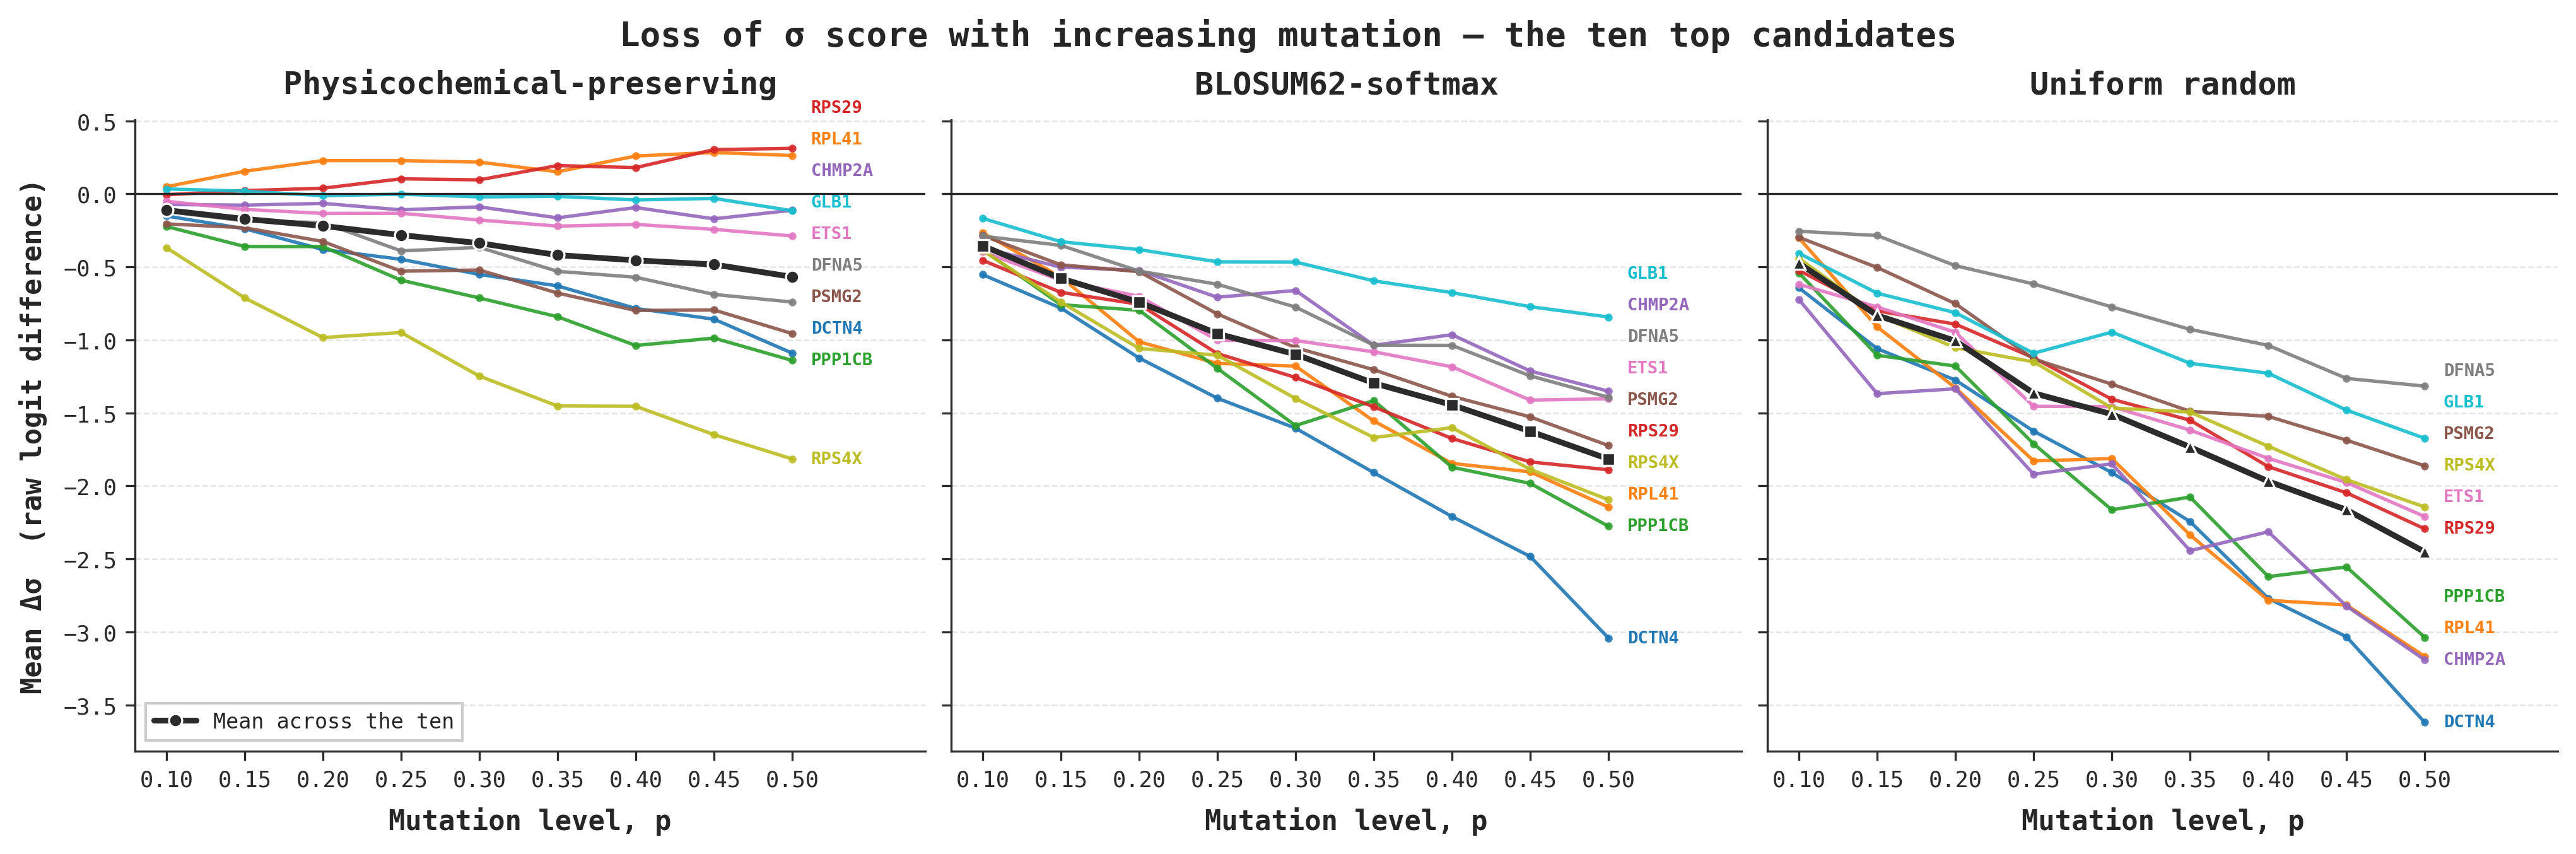

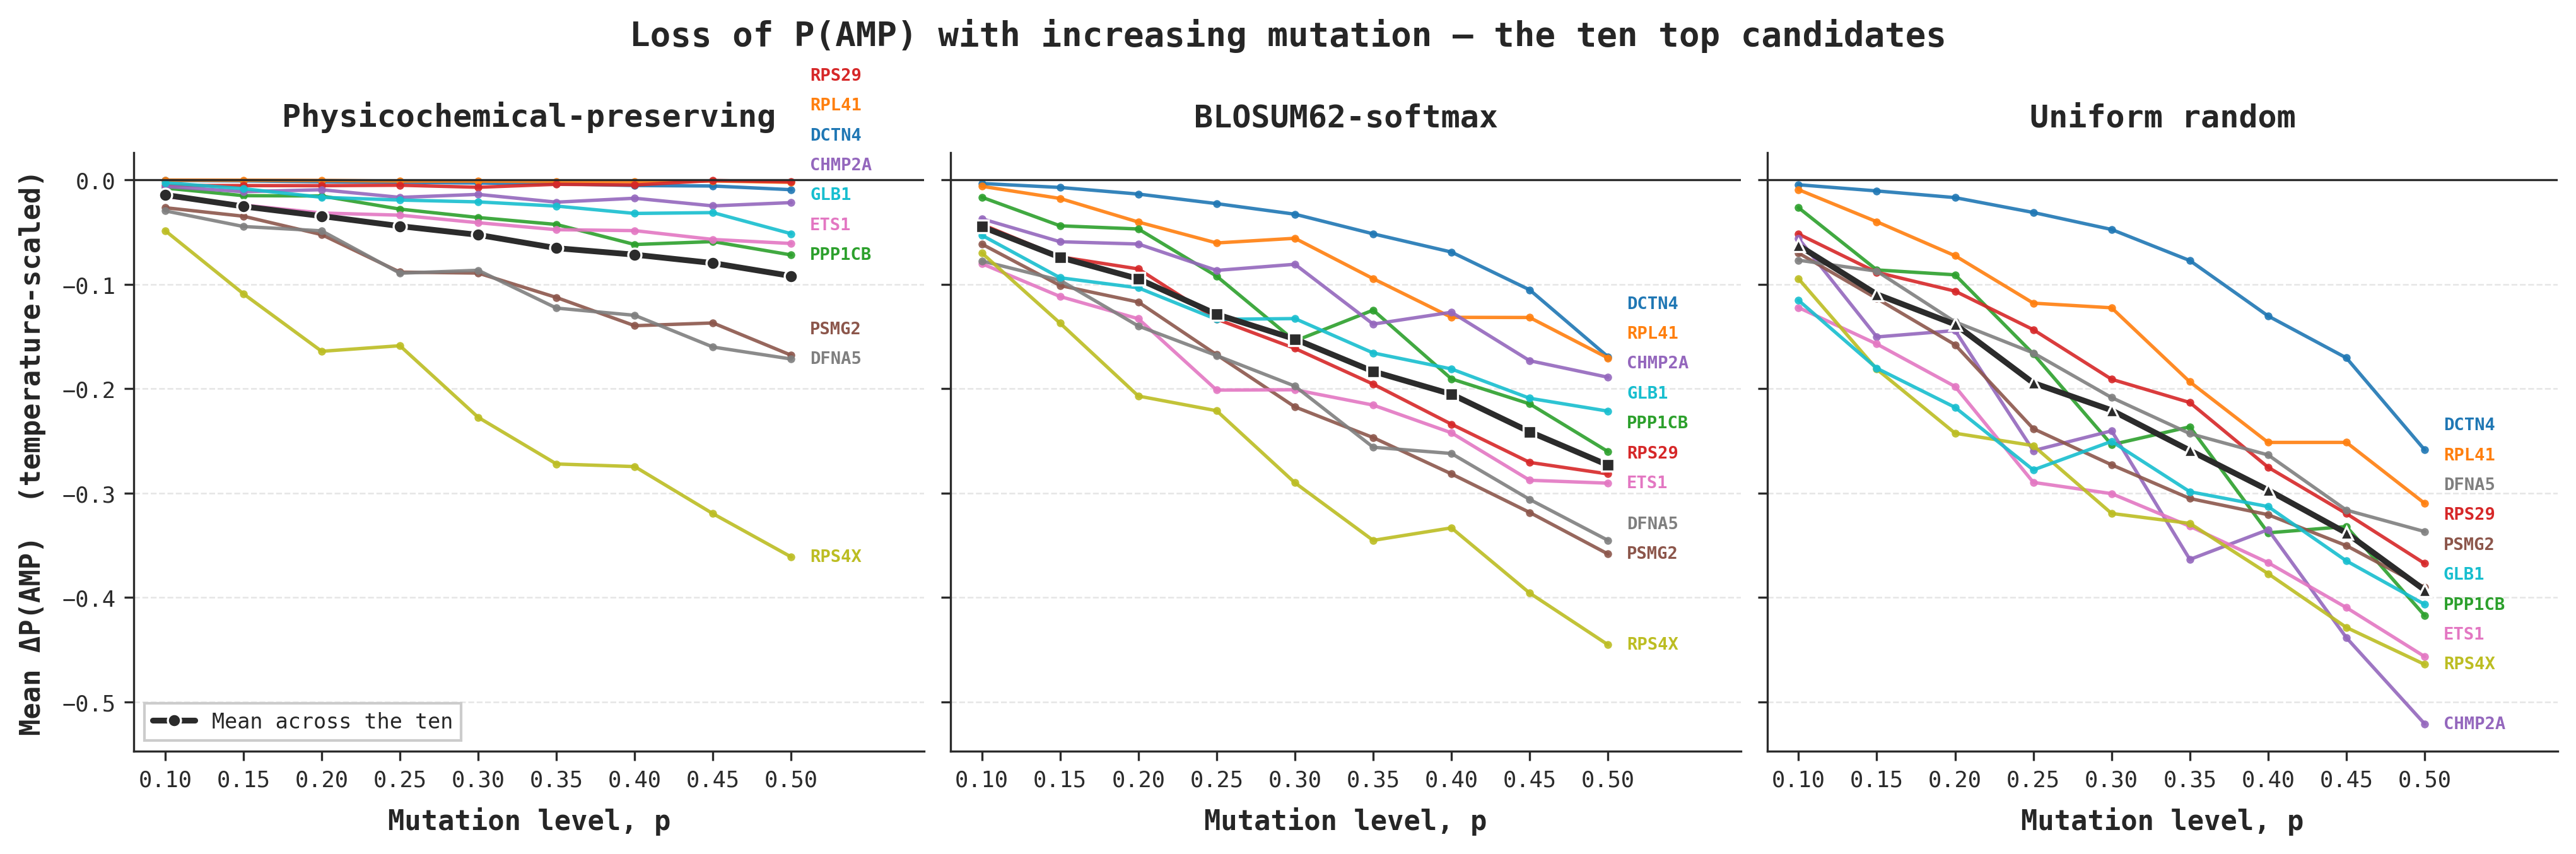

In [4]:
def plot_delta_vs_p(value: str, y_label: str, title: str) -> None:
    figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(13.5, 4.4), dpi=300,
                                sharey=True, layout="constrained")
    low, high = curves[value].min(), curves[value].max()
    gap = (high - low) * 0.055

    for axis, scheme in zip(axes, SCHEME_ORDER):
        subset = curves[curves["scheme"] == scheme]
        lines = subset.pivot(index="p", columns="parent_id", values=value)[PEPTIDE_ORDER]
        for peptide in PEPTIDE_ORDER:
            axis.plot(lines.index, lines[peptide], color=PEPTIDE_COLOR[peptide],
                      linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)

        ends = lines.iloc[-1].sort_values()
        for peptide, height in zip(ends.index, ladder_heights(ends.to_numpy(), gap)):
            axis.annotate(peptide, xy=(P_LEVELS[-1], ends[peptide]),
                          xytext=(P_LEVELS[-1] + 0.012, height), fontsize=6.5,
                          fontweight="bold", color=PEPTIDE_COLOR[peptide], va="center",
                          annotation_clip=False)

        mean = subset.groupby("p")[value].mean()
        axis.plot(mean.index, mean.to_numpy(), color=SPINE_COLOR, linewidth=2.2,
                  marker=SCHEME_MARKER[scheme], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, zorder=5, label="Mean across the ten")

        axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
        axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS)
        axis.set_xlim(right=P_LEVELS[-1] + 0.085)
        style_axes(axis)

    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_delta_vs_p(
    "delta_sigma",
    "Mean Δσ  (raw logit difference)",
    "Loss of σ score with increasing mutation — the ten top candidates",
)
plot_delta_vs_p(
    "delta_prob_AMP",
    "Mean ΔP(AMP)  (temperature-scaled)",
    "Loss of P(AMP) with increasing mutation — the ten top candidates",
)

### Retention versus p — scheme comparison

`retention` is the fraction of the 500 replicates in a cell still called AMP, so this is a survival
curve against mutation dose. The claim it tests: conservative substitutions should degrade the call
more slowly than uniform random ones. Bands are normal-approximation 95% CIs over the ten peptides.

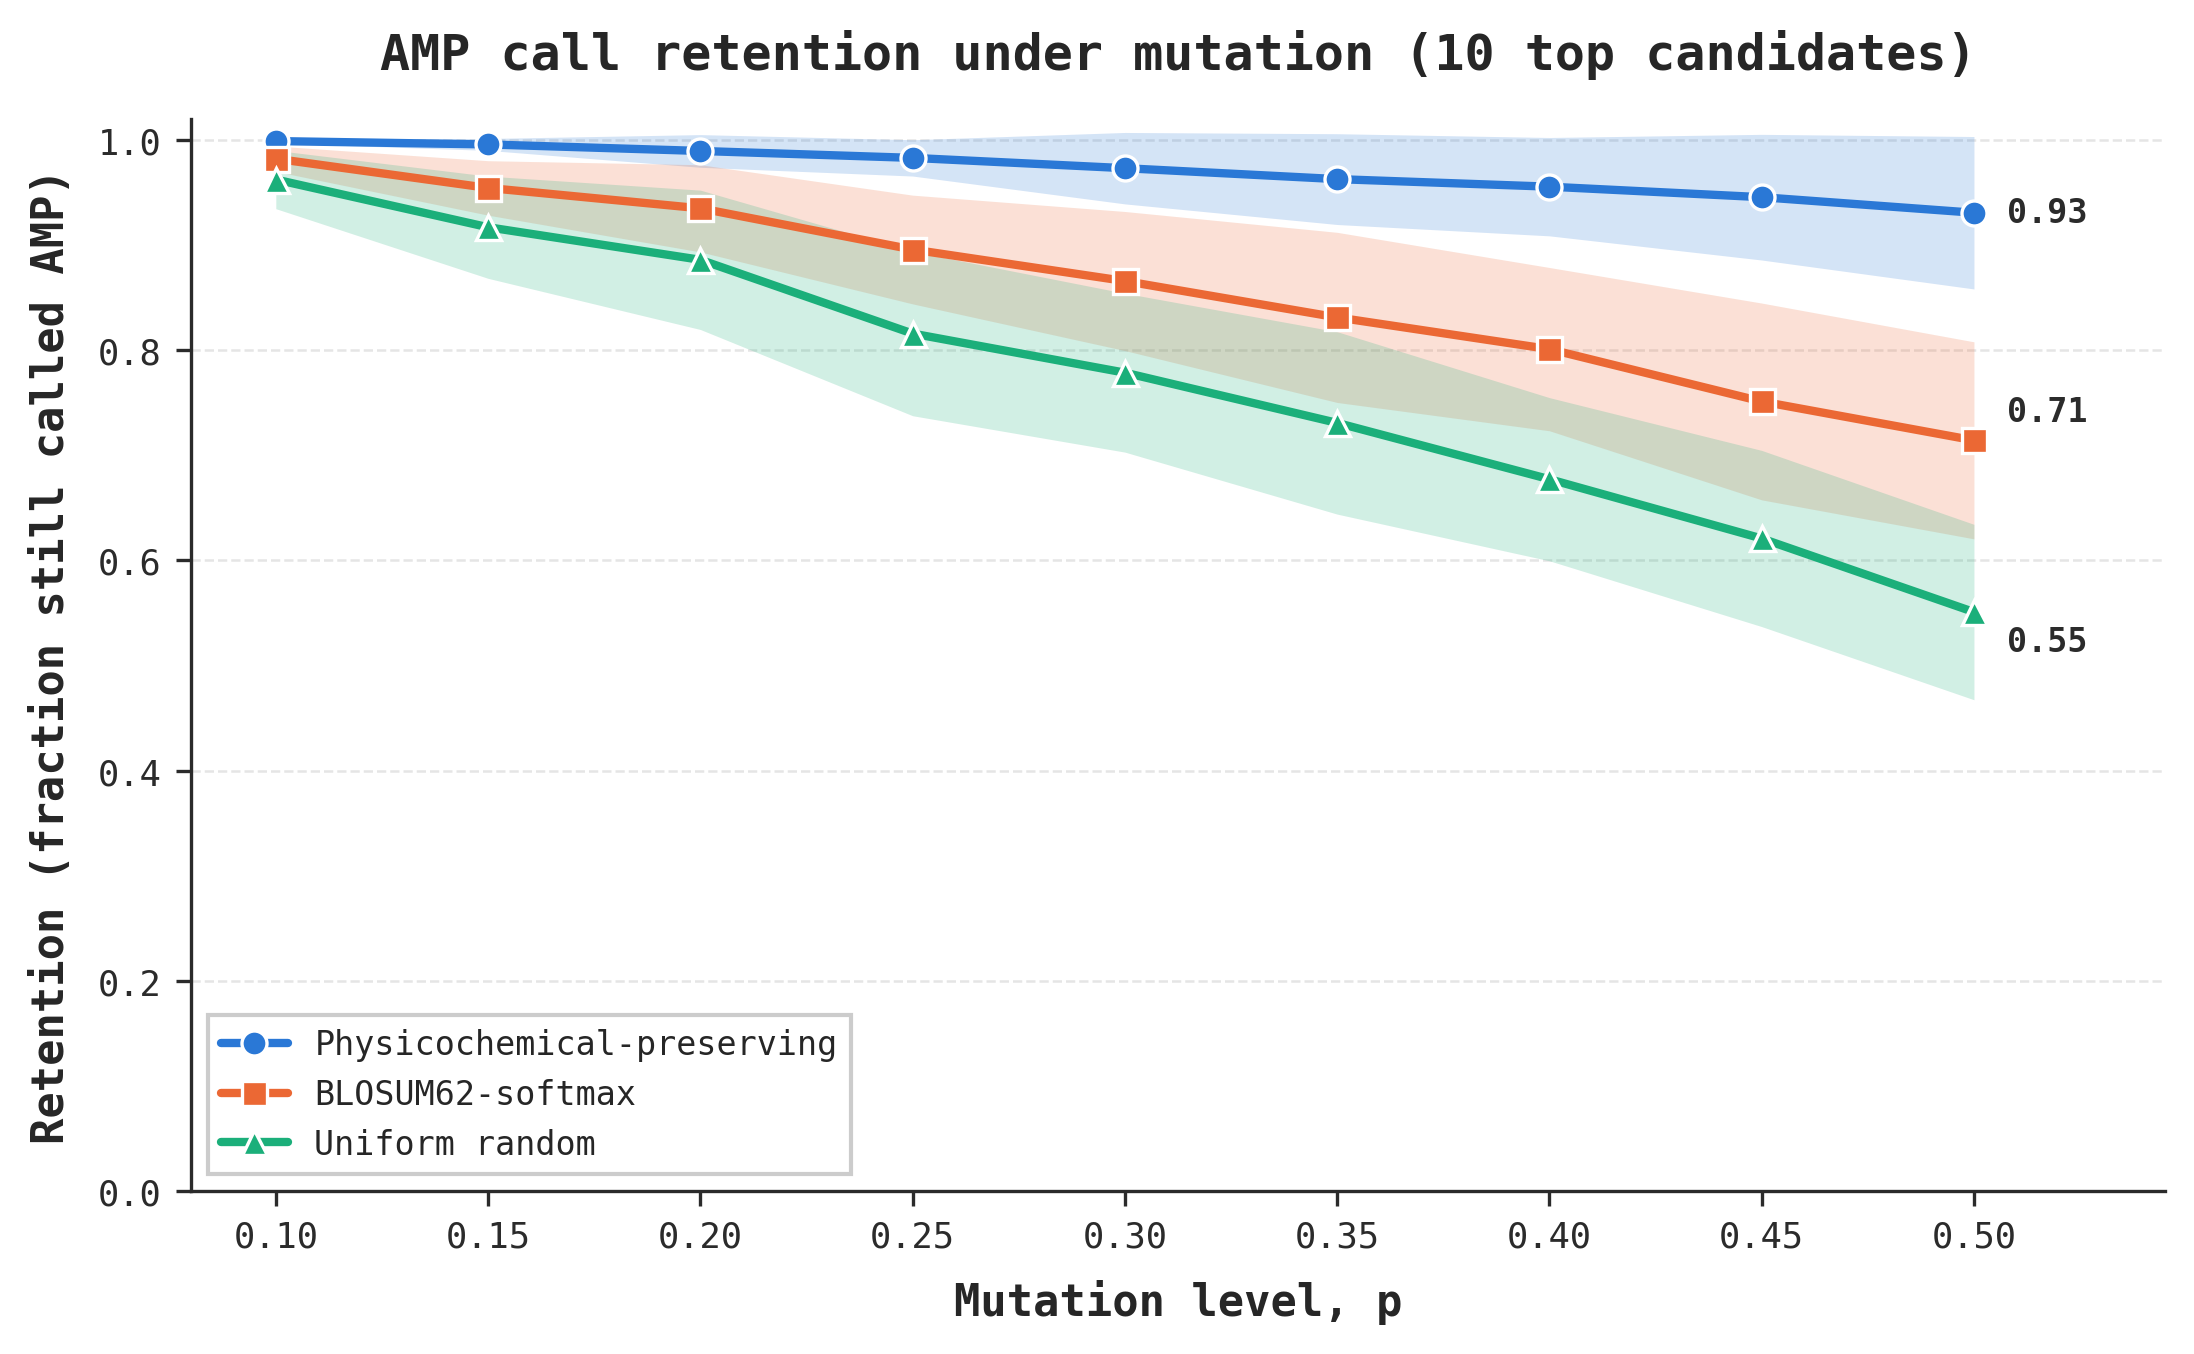

In [5]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across peptides with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


LABEL_OFFSET = {"physicochemical": 0.0, "blosum62": 7.0, "uniform": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for scheme in SCHEME_ORDER:
    stats = mean_ci(curves[curves["scheme"] == scheme], "retention")
    color = SCHEME_COLOR[scheme]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=SCHEME_MARKER[scheme], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=SCHEME_LABEL[scheme])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[scheme]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS)
axis.set_xlim(right=0.545)
axis.set_ylim(0, 1.02)
axis.legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under mutation ({len(parents)} top candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

### Per-peptide retention

The same curves split per peptide, which is what the ten-peptide set makes possible — the mean
above hides that the schemes separate for some candidates and collapse onto each other for others.
Panels are ordered by sustained σ, and the title carries each peptide's length and unmutated σ.

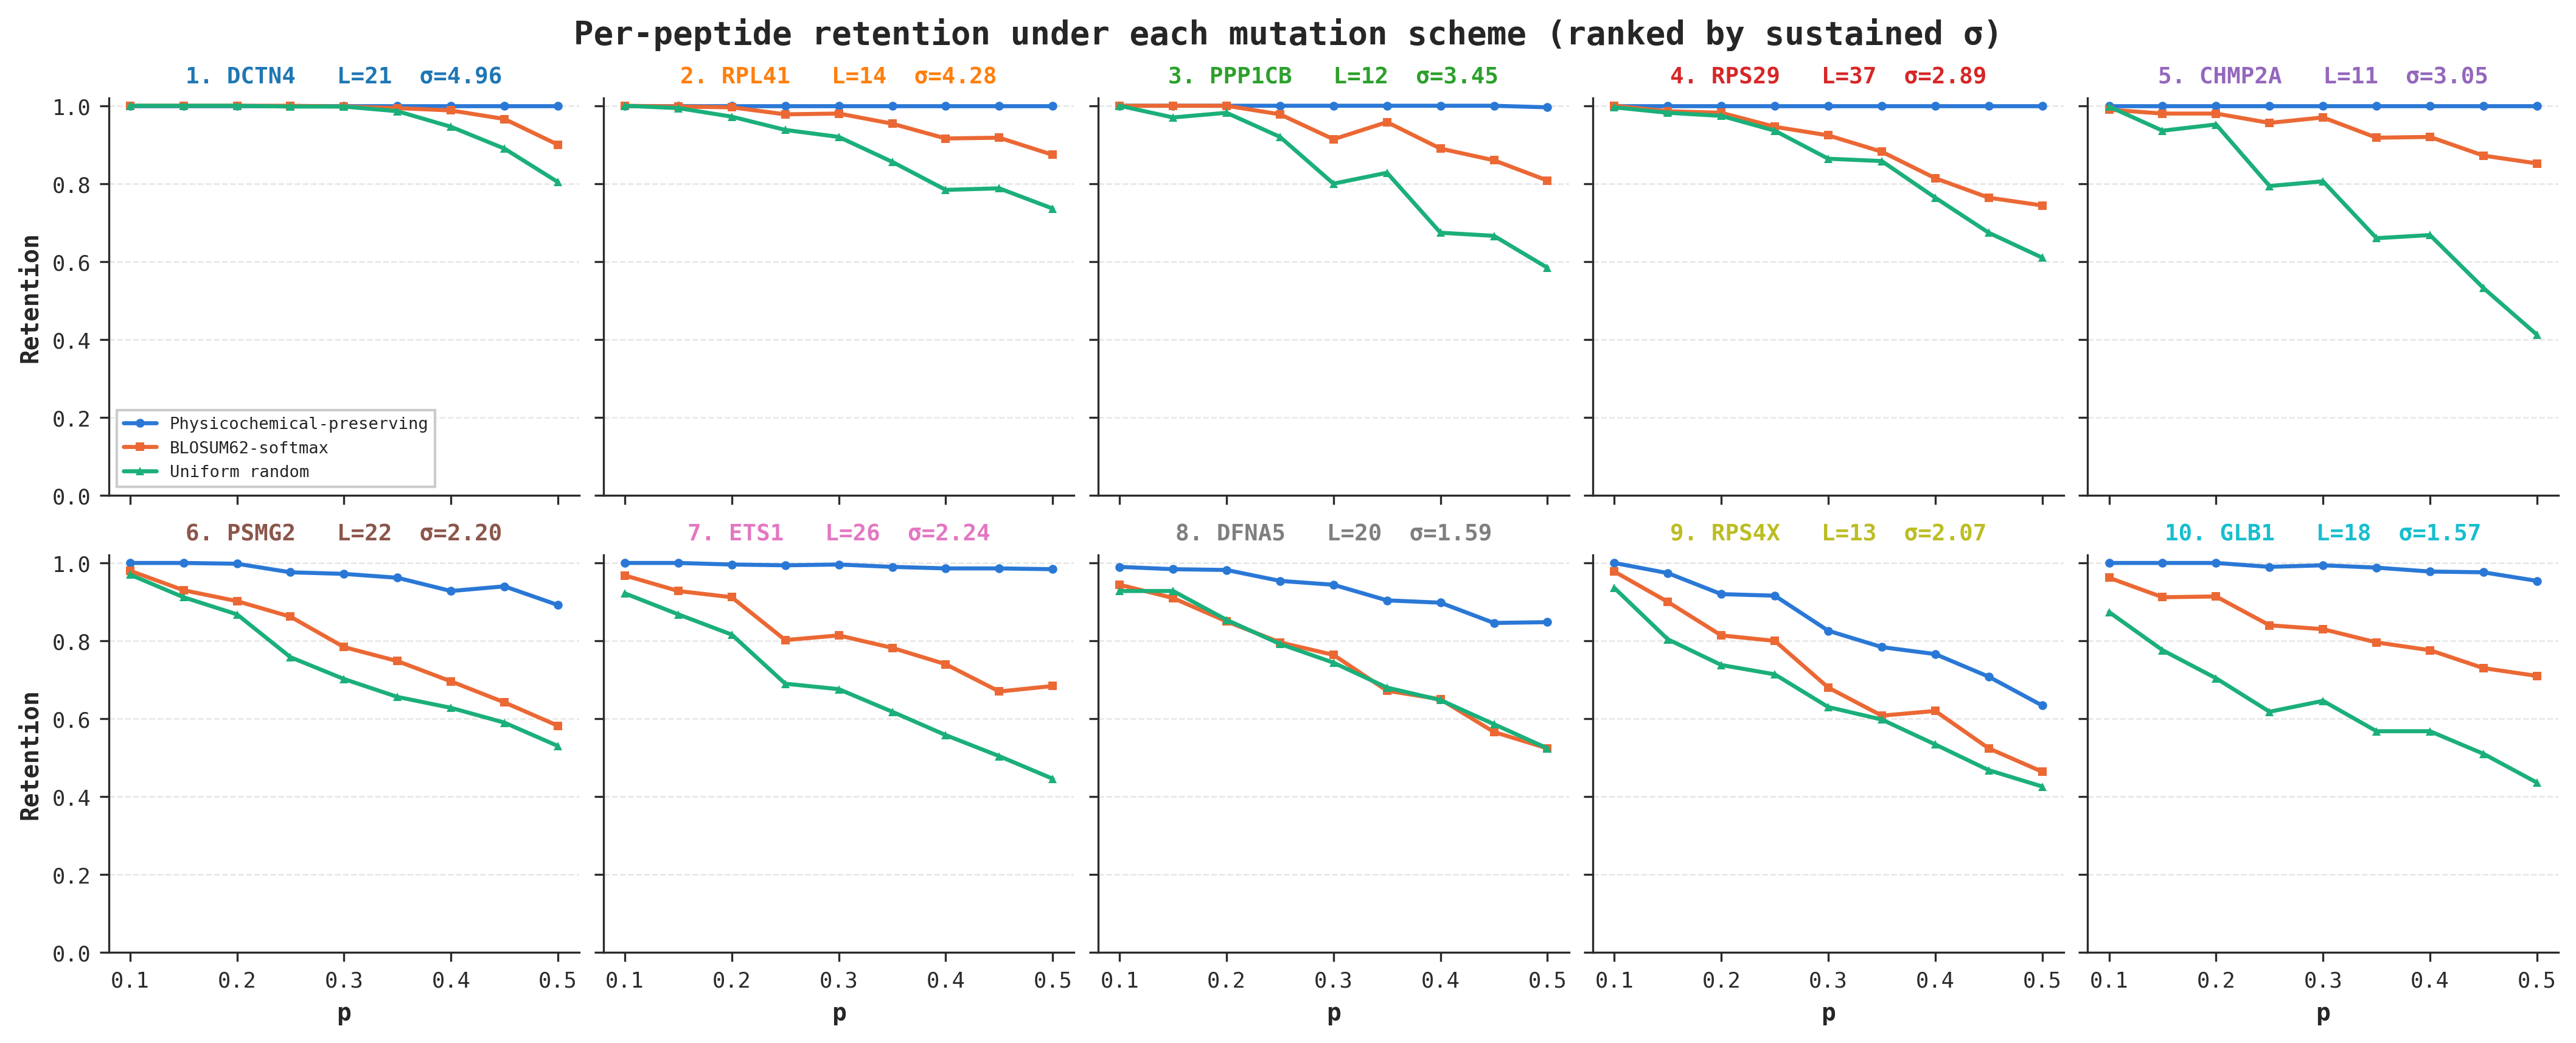

In [6]:
figure, axes = plt.subplots(2, 5, figsize=(14.0, 5.6), dpi=300, sharex=True, sharey=True,
                            layout="constrained")
for axis, peptide in zip(axes.flat, PEPTIDE_ORDER):
    subset = curves[curves["parent_id"] == peptide]
    for scheme in SCHEME_ORDER:
        cell = subset[subset["scheme"] == scheme]
        axis.plot(cell["p"], cell["retention"], color=SCHEME_COLOR[scheme], linewidth=1.6,
                  marker=SCHEME_MARKER[scheme], markersize=3.5, markeredgewidth=0,
                  label=SCHEME_LABEL[scheme])
    row = worst[worst["parent_id"] == peptide].iloc[0]
    axis.set_title(f"{int(row['rank'])}. {peptide}   L={int(row['length'])}  σ={row['parent_sigma']:.2f}",
                   fontsize=9, fontweight="bold", pad=6, color=PEPTIDE_COLOR[peptide])
    axis.set_xticks([0.1, 0.2, 0.3, 0.4, 0.5])
    axis.set_ylim(0, 1.02)
    style_axes(axis)

for axis in axes[1]:
    axis.set_xlabel("p", fontsize=9.5, fontweight="bold", labelpad=4)
for axis in axes[:, 0]:
    axis.set_ylabel("Retention", fontsize=9.5, fontweight="bold", labelpad=4)

axes[0, 0].legend(loc="lower left", fontsize=6.5, frameon=True, fancybox=False, framealpha=1)
figure.suptitle("Per-peptide retention under each mutation scheme (ranked by sustained σ)",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Retention per peptide and dose

The same numbers as a grid, which makes the dose at which each candidate starts losing its call
directly readable. Rows keep the sustained-σ ranking; columns are the nine nominal mutation levels.

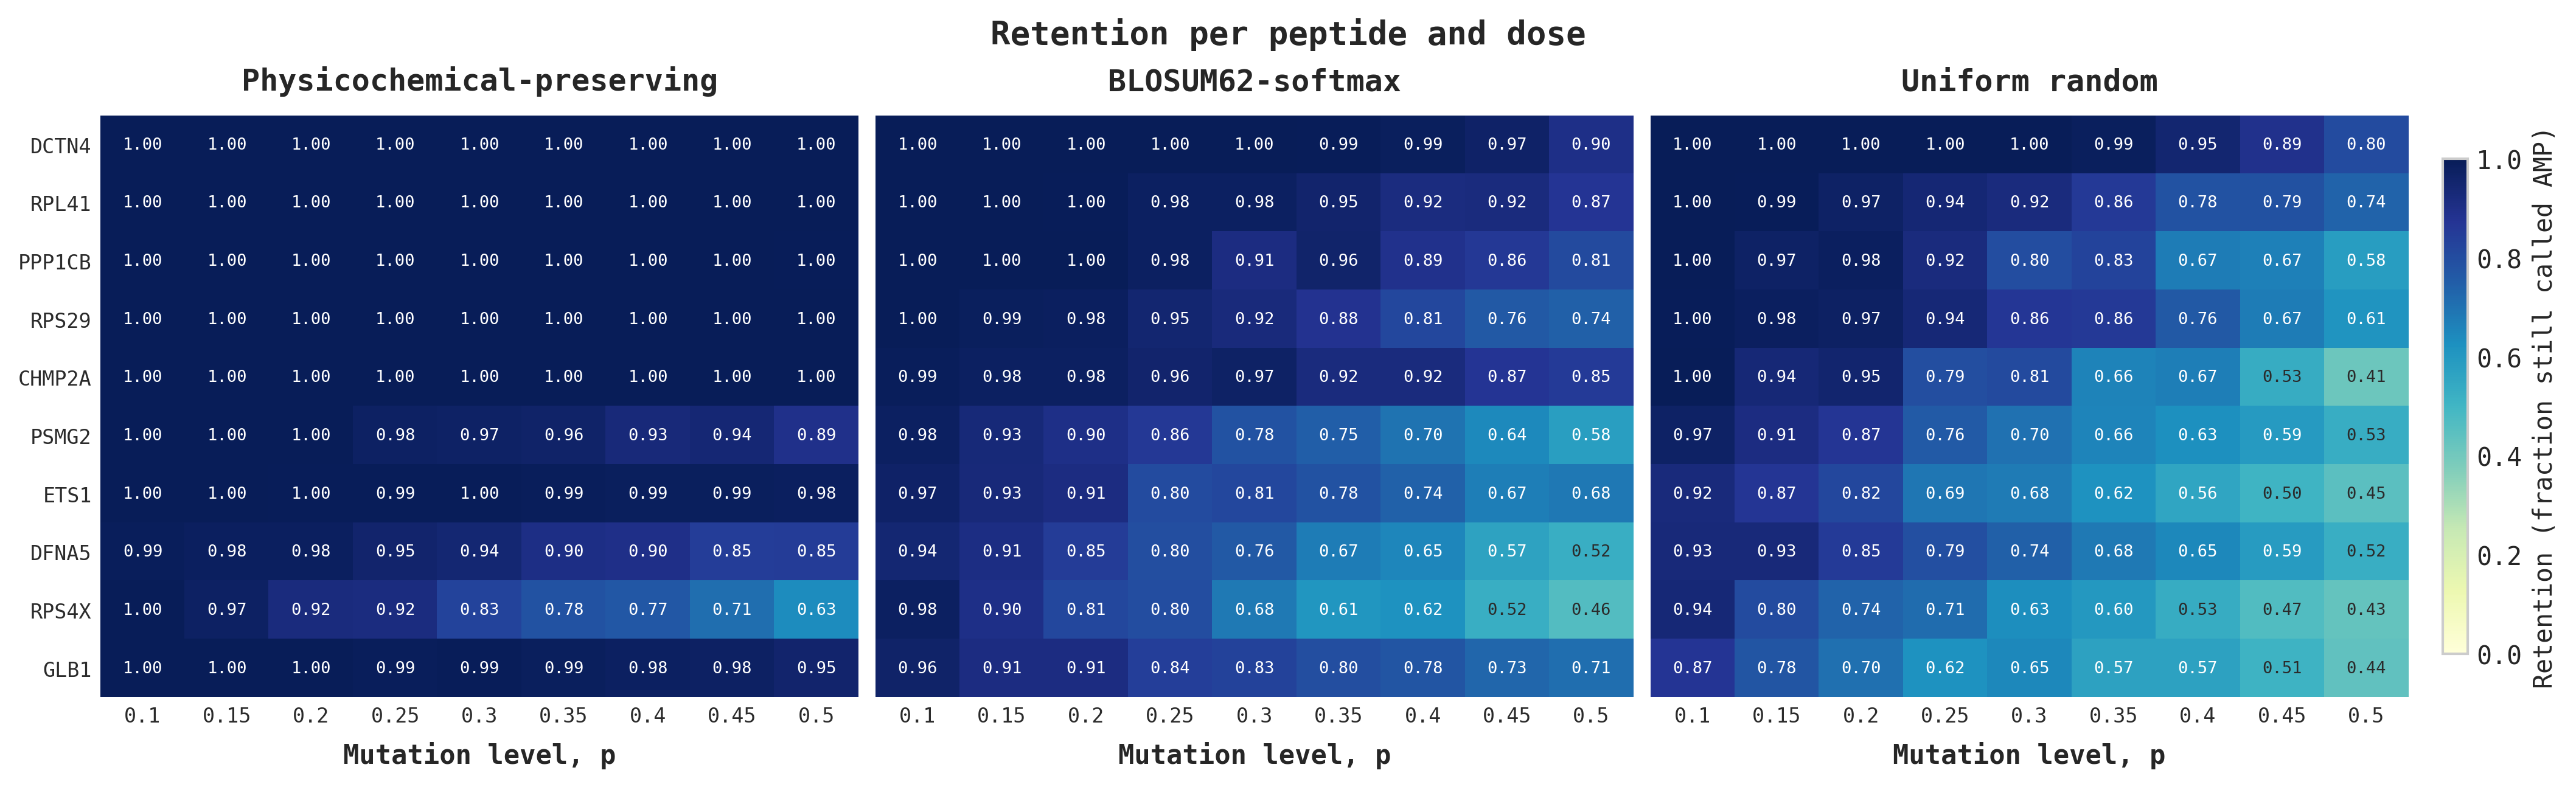

In [7]:
figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(14.0, 4.2), dpi=300,
                            sharey=True, layout="constrained")
for axis, scheme in zip(axes, SCHEME_ORDER):
    grid = (curves[curves["scheme"] == scheme]
            .pivot(index="parent_id", columns="p", values="retention")
            .loc[PEPTIDE_ORDER])
    image = axis.imshow(grid.to_numpy(), cmap="YlGnBu", vmin=0.0, vmax=1.0, aspect="auto")
    for row in range(grid.shape[0]):
        for column in range(grid.shape[1]):
            value = grid.iat[row, column]
            axis.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
                      color="white" if value > 0.55 else SPINE_COLOR)
    axis.set_xticks(range(len(P_LEVELS)), [f"{p:g}" for p in P_LEVELS], fontsize=8)
    axis.set_yticks(range(len(PEPTIDE_ORDER)), PEPTIDE_ORDER, fontsize=8)
    axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
    axis.grid(False)
    axis.tick_params(length=0, colors=SPINE_COLOR)
    for spine in axis.spines.values():
        spine.set_visible(False)

figure.colorbar(image, ax=axes, shrink=0.85, pad=0.015,
                label="Retention (fraction still called AMP)")
figure.suptitle("Retention per peptide and dose", fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Potency versus robustness

Orange is the unmutated σ, blue is the mean σ sustained across the sweep under the worst scheme,
and the gap between them is what mutation costs. The percentage is `mutation_sigma_retained`. A
peptide can rank well here either by starting high or by giving up little — the two are separated
by eye rather than collapsed into one score.

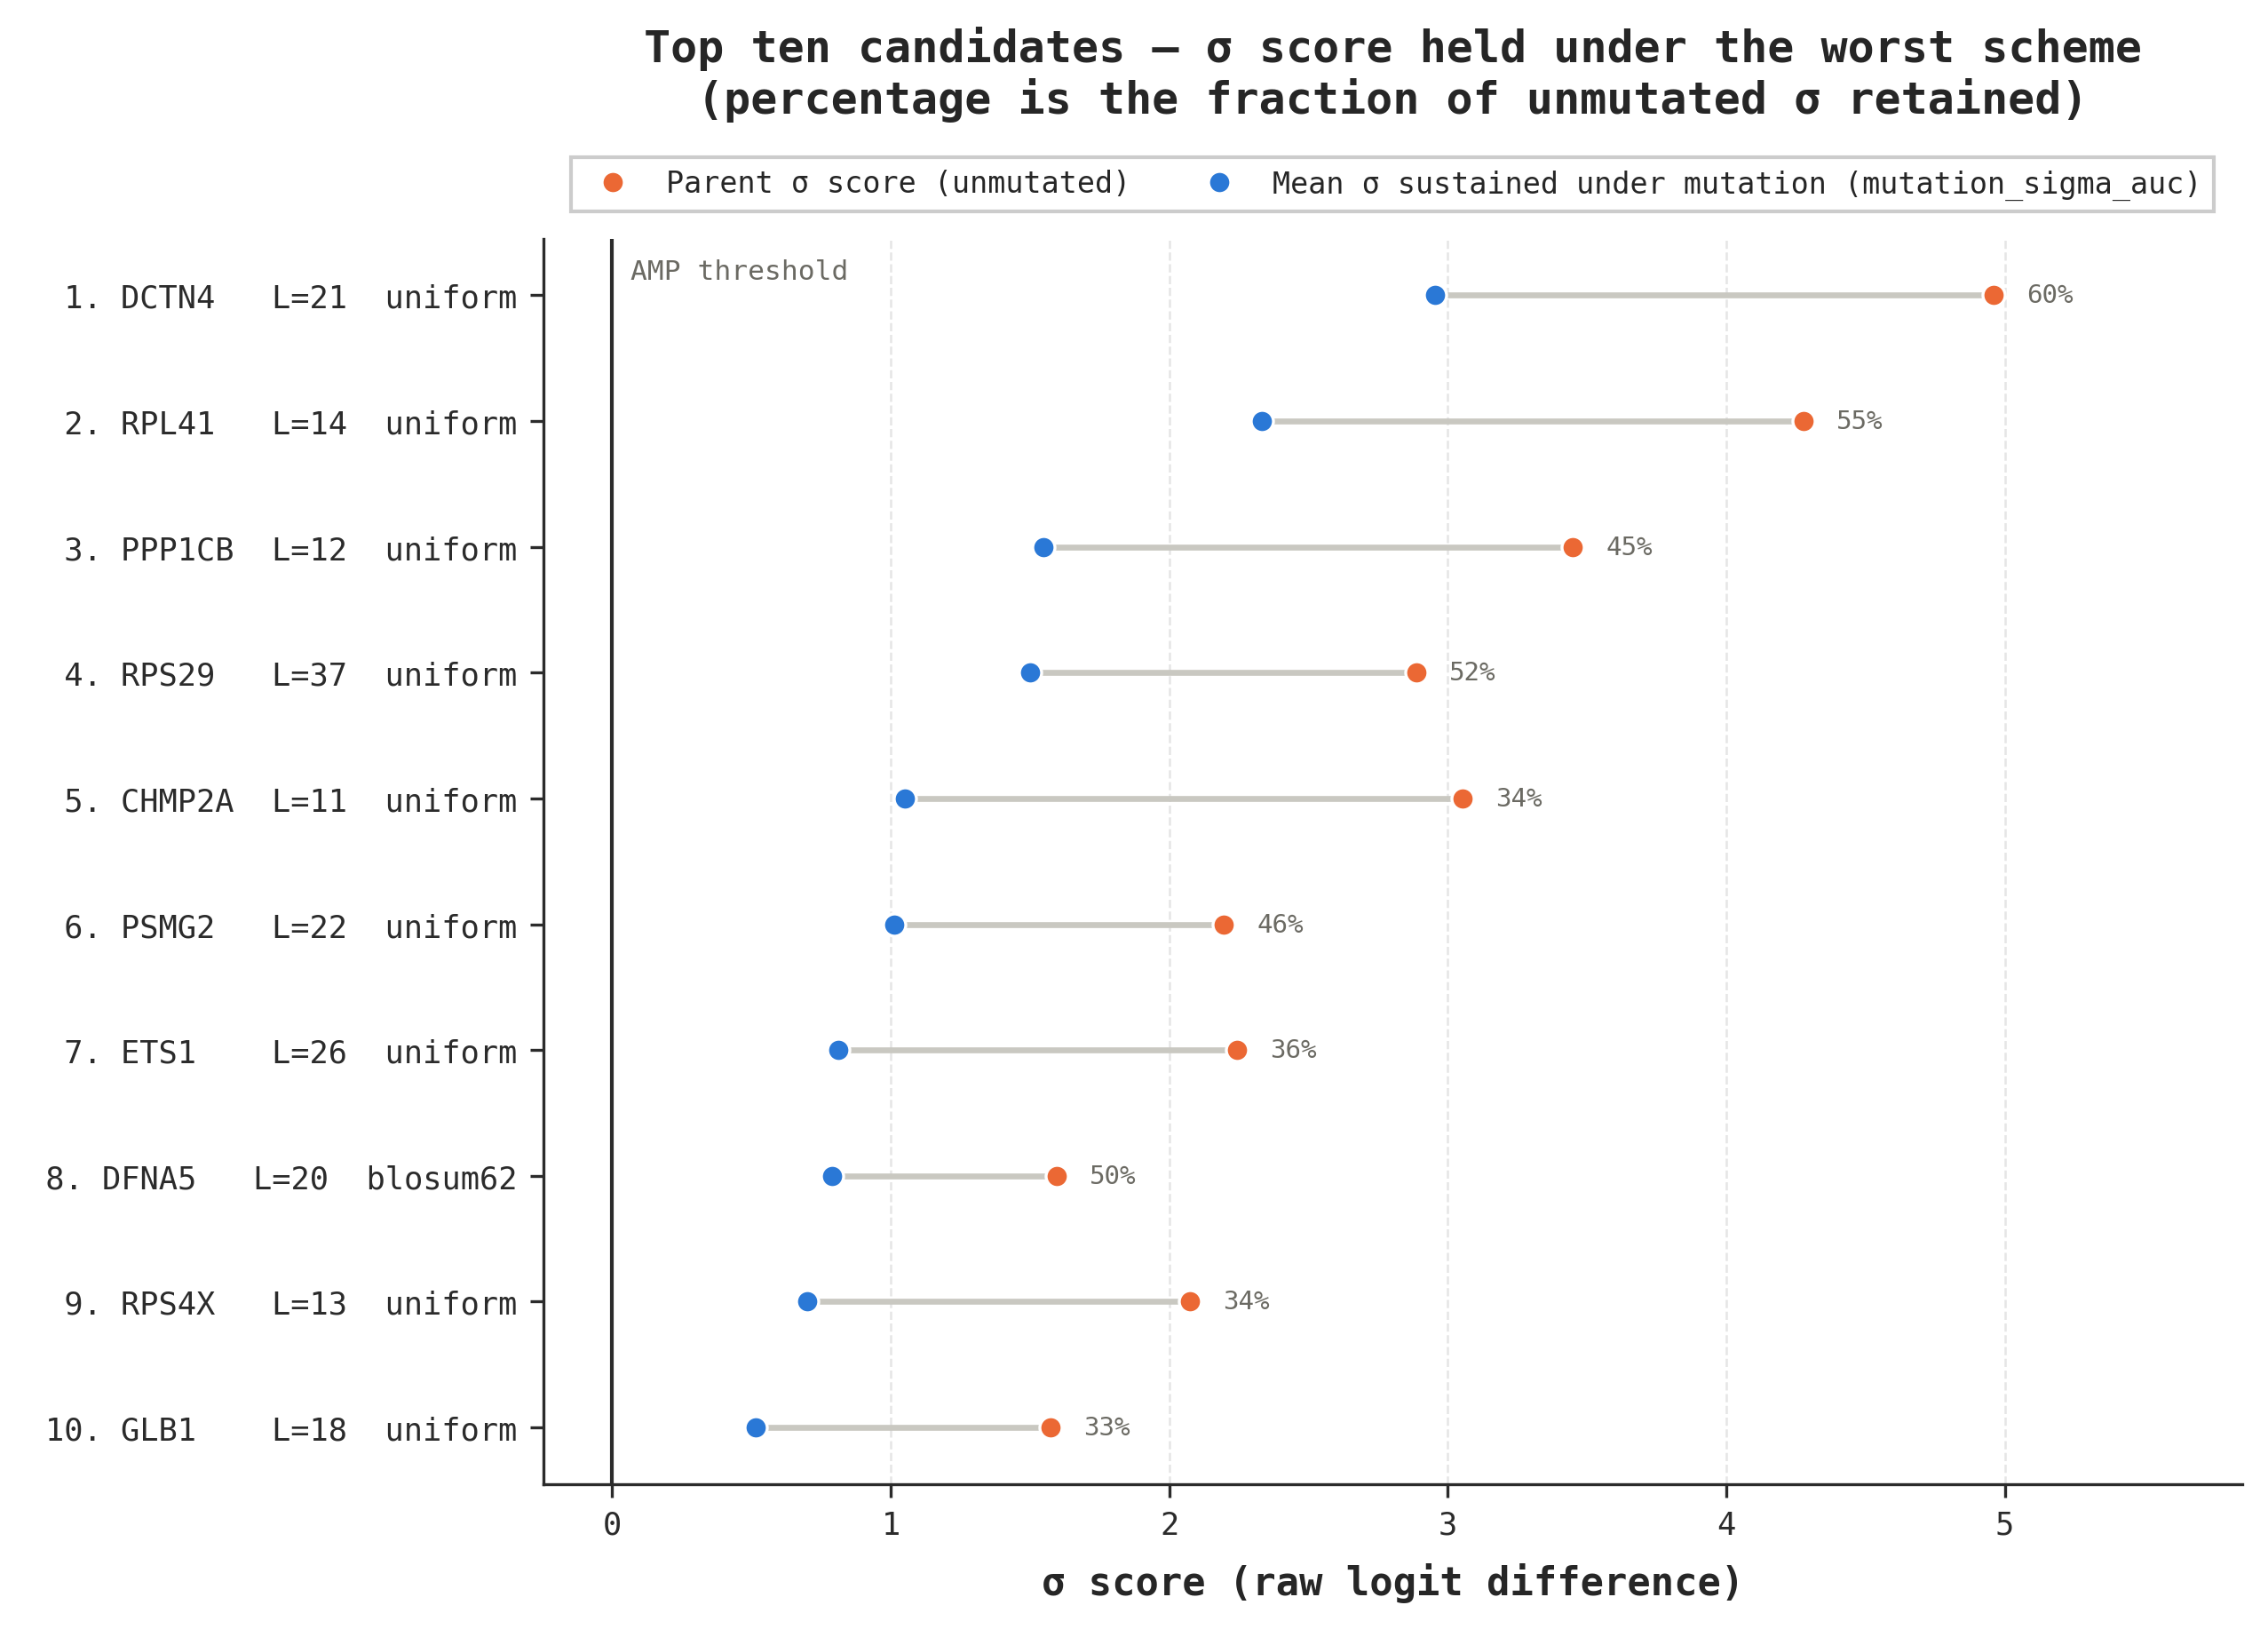

In [8]:
PARENT_COLOR = "#eb6834"
SUSTAINED_COLOR = "#2a78d6"

panel = worst.iloc[::-1]
positions = np.arange(len(panel))

figure, axis = plt.subplots(figsize=(8.4, 0.40 * len(panel) + 2.0), dpi=300, layout="constrained")
axis.hlines(positions, panel["mutation_sigma_auc"], panel["parent_sigma"],
            color="#c9c8c1", linewidth=1.6, zorder=1)
axis.plot(panel["parent_sigma"], positions, "o", markersize=6, color=PARENT_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Parent σ score (unmutated)")
axis.plot(panel["mutation_sigma_auc"], positions, "o", markersize=6, color=SUSTAINED_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Mean σ sustained under mutation (mutation_sigma_auc)")

for position, row in zip(positions, panel.itertuples()):
    axis.annotate(f"{row.mutation_sigma_retained:.0%}",
                  xy=(row.parent_sigma, position), textcoords="offset points",
                  xytext=(9, 0), fontsize=7, color="#6b6a63", va="center")

labels = [f"{rank:>2}. {pid:<7} L={length:>2}  {scheme}"
          for rank, pid, length, scheme in zip(panel["rank"], panel["parent_id"],
                                               panel["length"], panel["scheme"])]
axis.set_yticks(positions)
axis.set_yticklabels(labels)
axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
axis.annotate("AMP threshold", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
              textcoords="offset points", xytext=(5, -11), fontsize=7.5, color="#6b6a63")
axis.set_xlim(right=float(panel["parent_sigma"].max()) * 1.18)
axis.set_xlabel("σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_title("Top ten candidates — σ score held under the worst scheme\n"
               "(percentage is the fraction of unmutated σ retained)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=34)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
            fontsize=8, frameon=True, fancybox=False, framealpha=1)
style_axes(axis, grid_axis="x")
plt.show()

### Caveat — nominal `p` is not a distinct dose at these lengths

`k = floor(p·L + 0.5)`, so several nominal `p` levels collapse onto the same substitution count for
short peptides. Those cells re-measure a dose already measured, which shows up as a stair-step in
the curves above and makes `retention_auc` weight doses unevenly in a way that varies with length.

This bites harder here than on the full candidate set: these ten run from 11 to 37 aa, and the
shortest resolve the nine nominal levels into only six distinct substitution counts.

In [9]:
redundancy = curves.copy()
redundancy["duplicate_k"] = redundancy.duplicated(["parent_id", "scheme", "k_requested"])
by_peptide = redundancy.groupby("parent_id").agg(
    length=("length", "first"),
    cells=("duplicate_k", "size"),
    redundant=("duplicate_k", "sum"),
    distinct_k=("k_requested", "nunique"),
)
by_peptide["k_values"] = (redundancy.groupby("parent_id")["k_requested"]
                          .apply(lambda column: ", ".join(map(str, sorted(column.unique())))))
by_peptide["fraction"] = (by_peptide["redundant"] / by_peptide["cells"]).round(3)
by_peptide = by_peptide.loc[PEPTIDE_ORDER]

overall = redundancy["duplicate_k"].mean()
print(f"redundant cells: {redundancy['duplicate_k'].sum()} / {len(redundancy)} ({overall:.1%})")
print(f"variants spent re-measuring a known dose: "
      f"{redundancy.loc[redundancy['duplicate_k'], 'n_variants'].sum():,}")
display(by_peptide[["length", "distinct_k", "cells", "redundant", "fraction", "k_values"]])

redundant cells: 33 / 270 (12.2%)
variants spent re-measuring a known dose: 16,500


,length,distinct_k,cells,redundant,fraction,k_values
parent_id,,,,,,
DCTN4,21,9,27,0,0.000,"2, 3, 4, 5, 6, 7, 8, 9, 11"
RPL41,14,7,27,6,0.222,"1, 2, 3, 4, 5, 6, 7"
PPP1CB,12,6,27,9,0.333,"1, 2, 3, 4, 5, 6"
RPS29,37,9,27,0,0.000,"4, 6, 7, 9, 11, 13, 15, 17, 19"
CHMP2A,11,6,27,9,0.333,"1, 2, 3, 4, 5, 6"
PSMG2,22,9,27,0,0.000,"2, 3, 4, 6, 7, 8, 9, 10, 11"
ETS1,26,9,27,0,0.000,"3, 4, 5, 7, 8, 9, 10, 12, 13"
DFNA5,20,9,27,0,0.000,"2, 3, 4, 5, 6, 7, 8, 9, 10"
RPS4X,13,7,27,6,0.222,"1, 2, 3, 4, 5, 6, 7"


## Deletion — truncation from one end

Reads the latest `length_analysis --mode deletion` run over the same ten
(`gnn-alpha-deletion-…`). Each peptide is truncated from one terminus at a time by
`k = round(p·L)` residues, at `p = 0.05, 0.1, 0.2`, giving 10 × 2 × 3 = 60 variants.

Unlike the mutation sweep, **every variant is folded on its own** — truncation changes the
chain, so there is no fixed-backbone shortcut. Both this run and the extension run below fold
into the shared `generated/length_cache`, which is why their unextended baselines agree.

Two things to know before reading the figures:

- **Retention is 1.0 everywhere.** Not one of the 60 truncations loses the AMP call, so the
  retention curve that carries the signal on the 1,074-candidate set is flat here and is not
  plotted. Δσ is what moves.
- **`p` is the requested dose, `k` is what lands.** `k = floor(p·L + 0.5)` differs per peptide,
  and at these lengths several `p` levels collapse onto one `k` (CHMP2A and PPP1CB resolve all
  three into `k ∈ {1, 2}`). The figures plot `p`, where the ten share an axis; the table lists
  each peptide's `k`.

In [10]:
DELETION_CURVES_CSV = latest_run_csv(DATA_ROOT, "length_deletion_curves.csv")
DELETION_ROBUSTNESS_CSV = latest_run_csv(DATA_ROOT, "length_deletion_robustness.csv")

TERMINUS_ORDER = ["N", "C"]
TERMINUS_COLOR = {"N": "#2a78d6", "C": "#eb6834"}
TERMINUS_MARKER = {"N": "o", "C": "s"}

# margin_auc means the deletion sweep here, not the mutation one.
DELETION_RENAMES = SIGMA_RENAMES | {
    "delta_logit_margin": "delta_sigma",
    "margin_auc": "deletion_sigma_auc",
}
deletion_curves = pd.read_csv(DELETION_CURVES_CSV).rename(columns=DELETION_RENAMES)
deletion_robustness = pd.read_csv(DELETION_ROBUSTNESS_CSV).rename(columns=DELETION_RENAMES)

deletion_manifest = json.loads((DELETION_CURVES_CSV.parent / "run_manifest.json").read_text())
deletion_parents = deletion_robustness.drop_duplicates("parent_id").set_index("parent_id")["parent_sigma"]

DELETION_P_LEVELS = sorted(deletion_curves["p"].unique())
lost = deletion_curves[deletion_curves["pred"] == 0]

print("Run:   ", deletion_manifest["run_id"],
      f"({deletion_manifest['config']['effective']['deletion']})")
print("Curves:", DELETION_CURVES_CSV.name, f"({len(deletion_curves)} rows)")
print(f"p levels {DELETION_P_LEVELS}, termini {sorted(deletion_curves['terminus'].unique())}")
print(f"variants losing the AMP call: {len(lost)} / {len(deletion_curves)}")
# The length runs fold their own copies into generated/length_cache, so a parent's
# baseline here need not equal the mutation section's byte-for-byte.
drift = (deletion_parents - parents.set_index("parent_id")["parent_sigma"]).abs()
print(f"parent σ vs the mutation section: {int((drift < 1e-6).sum())}/{len(drift)} identical, "
      f"largest gap {drift.max():.3f} ({drift.idxmax()})")

Run:    2026-11-12_12-21 ({'p_levels': [0.05, 0.1, 0.2], 'termini': ['N', 'C']})
Curves: length_deletion_curves.csv (60 rows)
p levels [np.float64(0.05), np.float64(0.1), np.float64(0.2)], termini ['C', 'N']
variants losing the AMP call: 0 / 60
parent σ vs the mutation section: 8/10 identical, largest gap 0.319 (DFNA5)


### Δσ and ΔP(AMP) versus deletion level

The x axis is **`p`, the requested fraction**, so all ten peptides share the same three
positions and the mean across them is defined at each one.

The residues actually removed are `k = floor(p·L + 0.5)`, which is not the same ladder for every
peptide — and that is why the earlier draft of this figure had lines starting and stopping at
different places:

- **RPS29** (L = 37) starts at `k = 2`, because `0.05 × 37 = 1.85` rounds up. Every other peptide
  starts at `k = 1`.
- At the top dose the ladders are nothing alike: `k = 2` for CHMP2A (L = 11) against `k = 7` for
  RPS29.
- At the short end successive `p` levels collapse onto one `k`: CHMP2A and PPP1CB both give
  `k = 1` at `p = 0.05` and again at `p = 0.1`, so those two points are the same variant scored
  twice and the line is flat there by construction.

The table below lists each peptide's `k` at all three levels, so nothing is lost by plotting `p`.

The **N panel's x axis runs right to left**, so the pair reads the way the peptide does — the N end on the left, the C end on the right, each one worked on from the outside in.

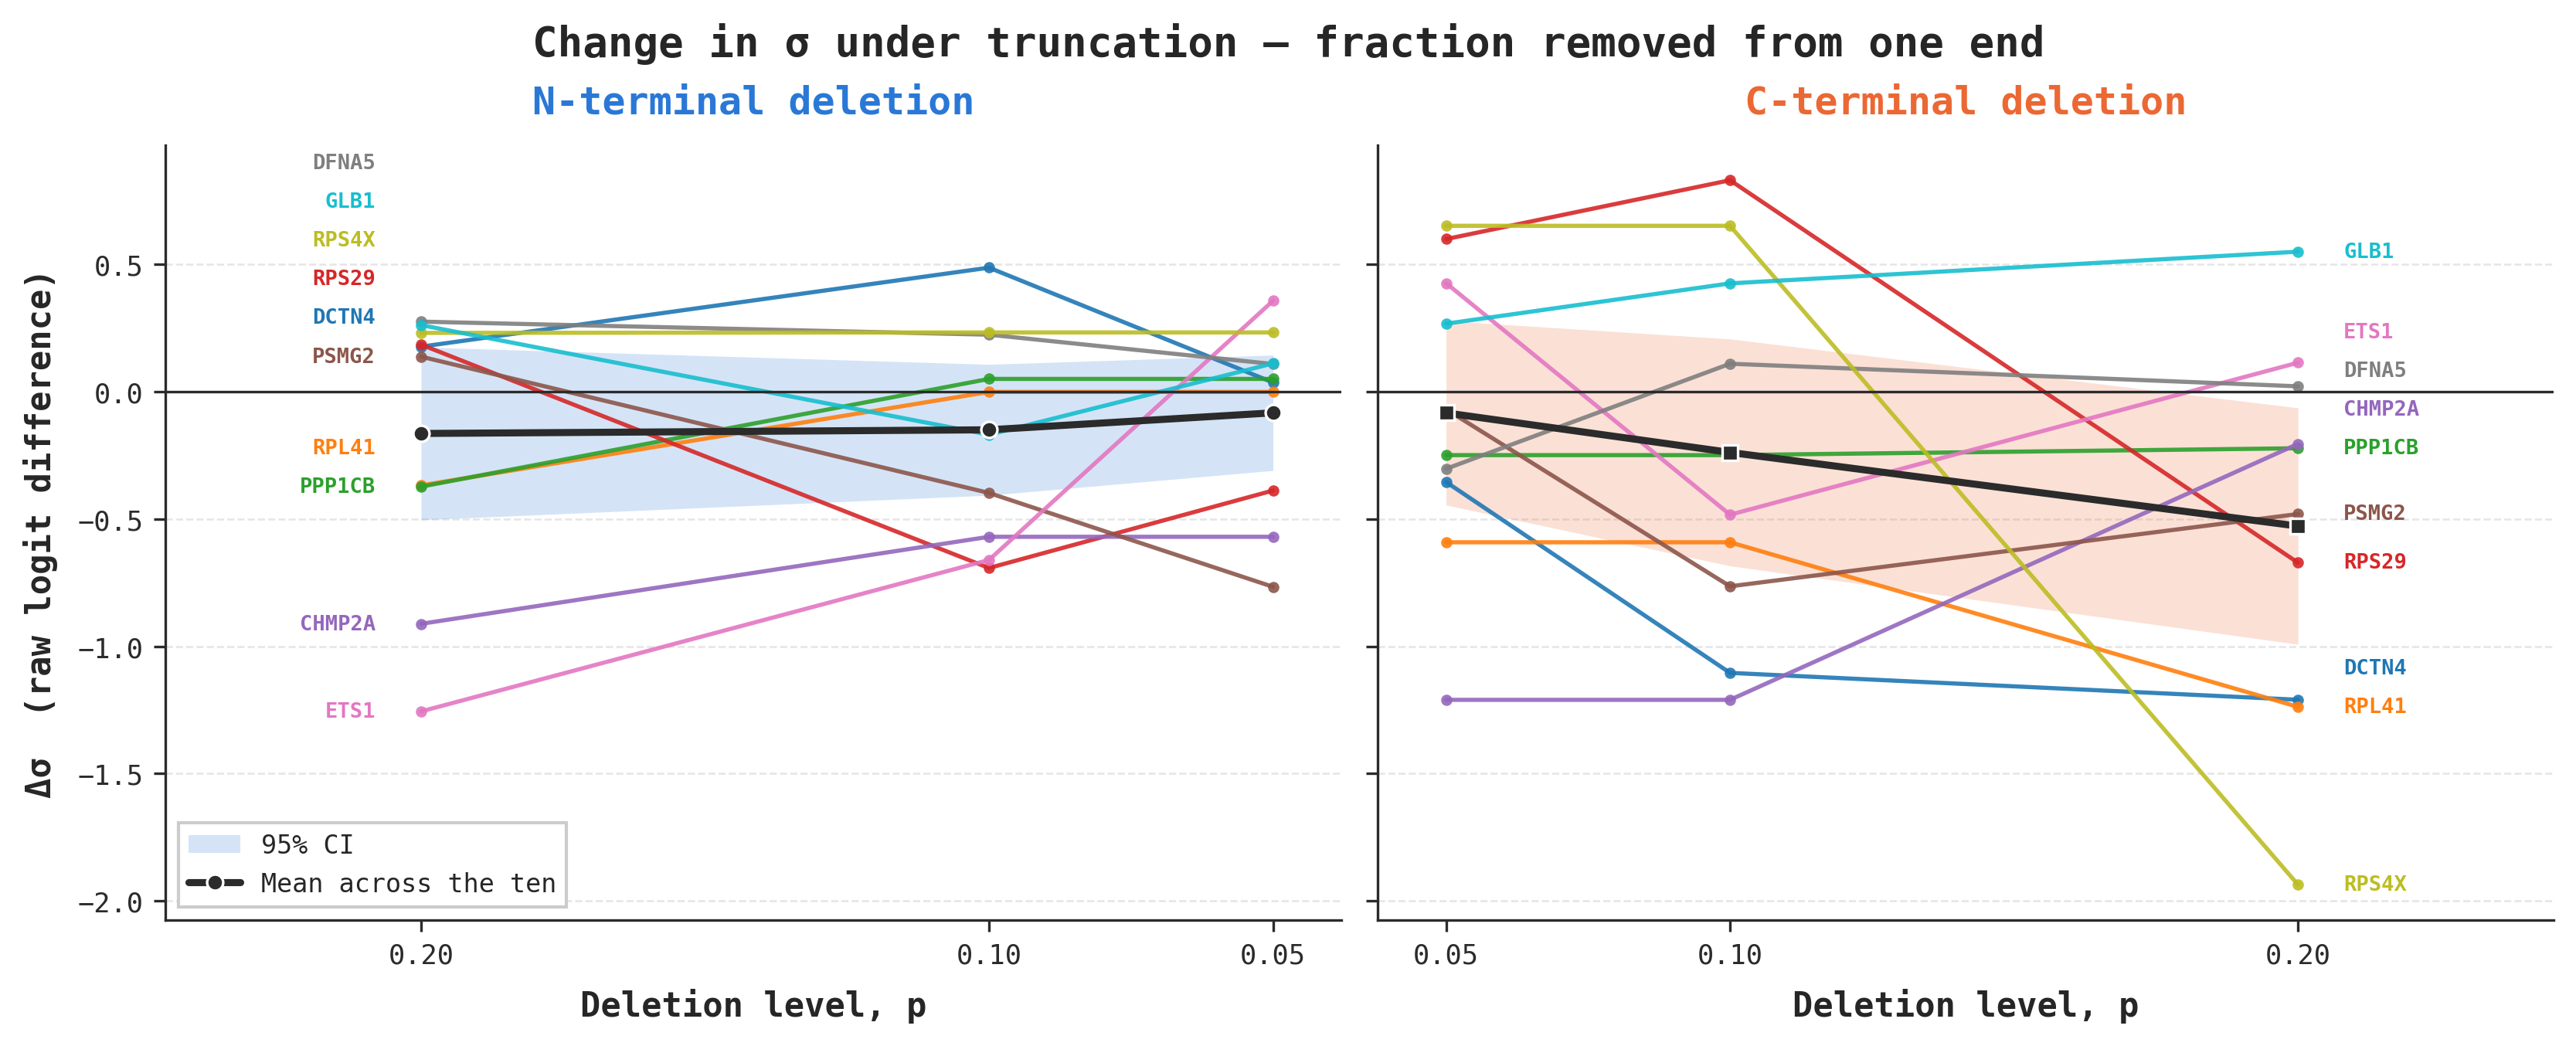

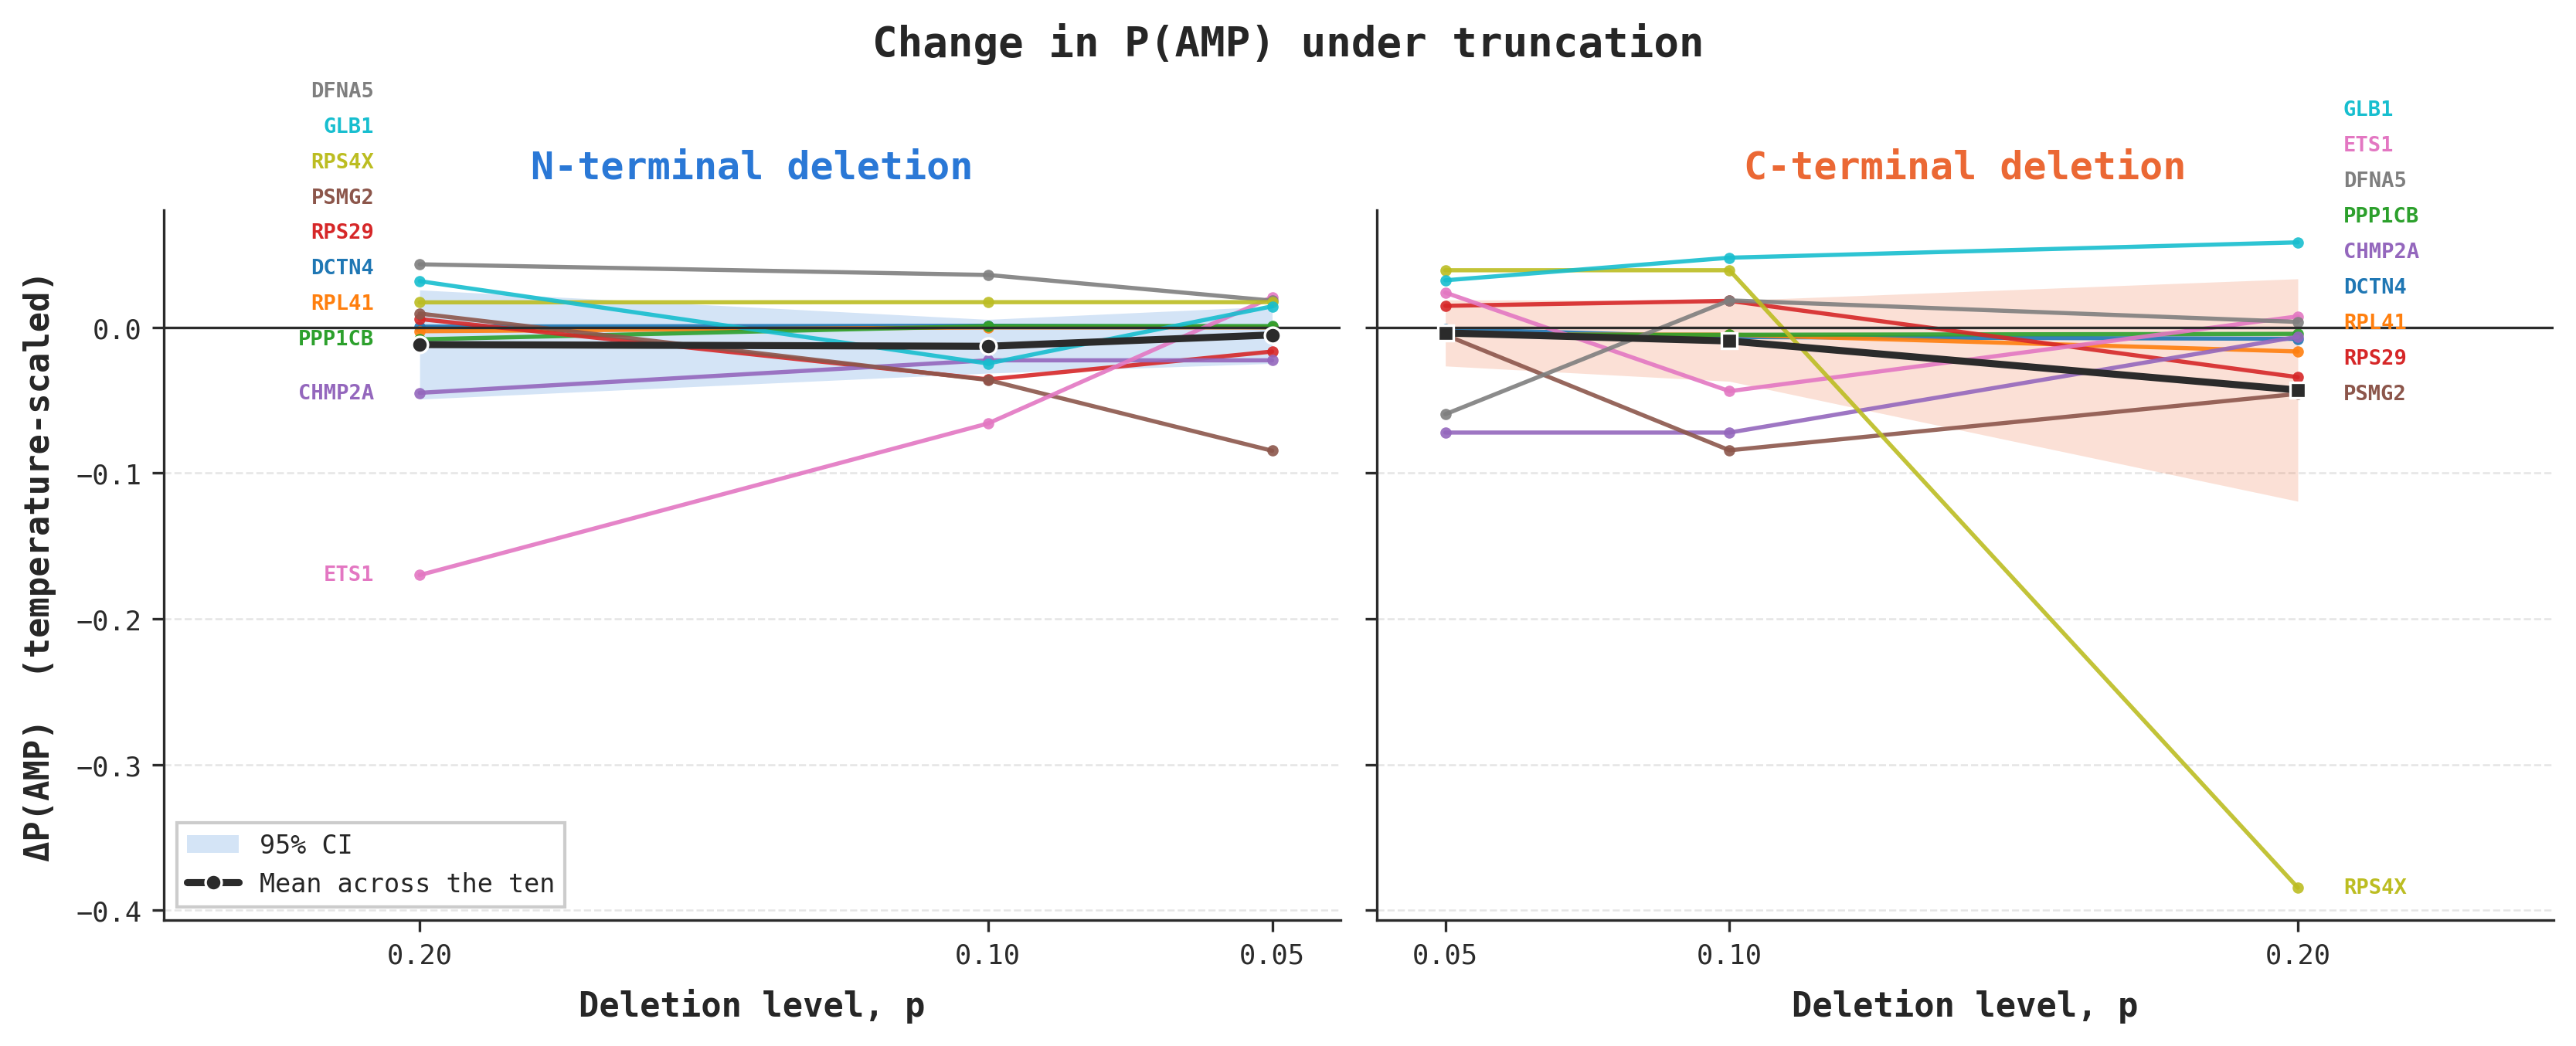

In [11]:
def plot_deletion_vs_p(value: str, y_label: str, title: str) -> None:
    """x is p, the requested fraction, so all ten share the same three positions.

    k = floor(p*L + 0.5) differs per peptide - the table below lists each one's - so an
    axis in residues gives every peptide its own start and end point.
    """
    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(11.0, 4.4), dpi=300,
                                sharey=True, layout="constrained")
    low, high = deletion_curves[value].min(), deletion_curves[value].max()
    gap = (high - low) * 0.055

    for axis, terminus in zip(axes, TERMINUS_ORDER):
        subset = deletion_curves[deletion_curves["terminus"] == terminus]
        lines = subset.pivot(index="p", columns="parent_id", values=value)[PEPTIDE_ORDER]
        for peptide in PEPTIDE_ORDER:
            axis.plot(lines.index, lines[peptide], color=PEPTIDE_COLOR[peptide], linewidth=1.3,
                      marker="o", markersize=3.5, markeredgewidth=0, alpha=0.9)

        ends = lines.iloc[-1].sort_values()
        for peptide, height in zip(ends.index, ladder_heights(ends.to_numpy(), gap)):
            axis.annotate(peptide, xy=(DELETION_P_LEVELS[-1], ends[peptide]),
                          xytext=(DELETION_P_LEVELS[-1] + 0.008, height), fontsize=6.5,
                          fontweight="bold", color=PEPTIDE_COLOR[peptide], va="center",
                          ha="right" if terminus == "N" else "left", annotation_clip=False)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=TERMINUS_COLOR[terminus],
                          alpha=0.2, linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=SPINE_COLOR, linewidth=2.2,
                  marker=TERMINUS_MARKER[terminus], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, zorder=5, label="Mean across the ten")

        axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
        axis.set_title(f"{terminus}-terminal deletion", fontsize=TITLE_SIZE, fontweight="bold",
                       pad=10, color=TERMINUS_COLOR[terminus])
        axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(DELETION_P_LEVELS)
        # The N panel runs right to left, so the two panels together read as the
        # peptide does: the N end on the left, the C end on the right, each eaten
        # away from the outside in.
        span = (DELETION_P_LEVELS[0] - 0.012, DELETION_P_LEVELS[-1] + 0.045)
        axis.set_xlim(*(span[::-1] if terminus == "N" else span))
        style_axes(axis)

    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_deletion_vs_p(
    "delta_sigma",
    "Δσ  (raw logit difference)",
    "Change in σ under truncation — fraction removed from one end",
)
plot_deletion_vs_p(
    "delta_prob_AMP",
    "ΔP(AMP)  (temperature-scaled)",
    "Change in P(AMP) under truncation",
)

### Per-terminus summary

`sigma_auc` is the mean σ held across the three doses and `sigma_slope` is dσ/dp, so a positive
slope means truncation *raised* the score. Rows keep the sustained-σ ranking from the mutation
section.

In [12]:
deletion_summary = (
    deletion_robustness.pivot(index="parent_id", columns="terminus",
                              values=["deletion_sigma_auc", "mean_delta_prob_AMP", "sigma_slope"])
    .loc[PEPTIDE_ORDER]
)
deletion_summary.columns = [f"{terminus}_{name.replace('deletion_sigma_auc', 'sigma_auc')}"
                            for name, terminus in deletion_summary.columns]
k_by_peptide = (deletion_curves[deletion_curves["terminus"] == "N"]
                .sort_values("p").groupby("parent_id")["k"]
                .apply(lambda column: ", ".join(map(str, column))))
deletion_summary.insert(0, "parent_sigma", deletion_parents.loc[PEPTIDE_ORDER])
deletion_summary.insert(0, "k at p=0.05/0.1/0.2", k_by_peptide.loc[PEPTIDE_ORDER])
deletion_summary.insert(0, "length", deletion_robustness.drop_duplicates("parent_id")
                        .set_index("parent_id")["length"].loc[PEPTIDE_ORDER])

numeric = [column for column in deletion_summary.columns if column not in
           {"length", "k at p=0.05/0.1/0.2"}]
display(deletion_summary.style.format("{:.3f}", subset=numeric)
        .format("{:.0f}", subset=["length"]))

,length,k at p=0.05/0.1/0.2,parent_sigma,C_sigma_auc,N_sigma_auc,C_mean_delta_prob_AMP,N_mean_delta_prob_AMP,C_sigma_slope,N_sigma_slope
parent_id,,,,,,,,,
DCTN4,21,"1, 2, 4",4.960,3.945,5.269,-0.005,0.001,-5.041,0.361
RPL41,14,"1, 1, 3",4.376,3.568,4.252,-0.009,-0.001,-4.619,-2.625
PPP1CB,12,"1, 1, 2",3.448,3.208,3.357,-0.005,-0.002,0.193,-3.025
RPS29,37,"2, 4, 7",2.887,3.179,2.538,-0.000,-0.016,-9.414,4.531
CHMP2A,11,"1, 1, 2",3.052,2.177,2.368,-0.050,-0.030,7.184,-2.443
PSMG2,22,"1, 2, 4",2.196,1.642,1.915,-0.045,-0.037,-1.946,5.934
ETS1,26,"1, 3, 5",2.243,2.110,1.553,-0.004,-0.072,-0.932,-10.069
DFNA5,20,"1, 2, 4",1.275,1.287,1.498,-0.012,0.032,1.725,1.025
RPS4X,13,"1, 1, 3",2.074,1.863,2.306,-0.102,0.017,-18.494,-0.013


## Insertion — extension into the native flanks

Reads the latest `length_analysis` extension run (`gnn-alpha-insertion-…`). Each peptide is
grown back into the residues that flank it in its source protein, up to
`max_flank_fraction = 0.5` of its own length on each side, at `stride = 1`, taking the full
left × right **product** — 862 variants from 11 to 56 aa, each one folded separately.

The flank, not the fraction, is the binding limit for two of them: **RPL41** starts at its
protein's N-terminus, so it has no left flank at all and only grows on the C side, and **RPS29**
has a single residue to its left against an 18-residue allowance.

Extension is the one direction that can *improve* a candidate, and 8 of the 10 do.

In [13]:
INSERTION_CSV = latest_run_csv(DATA_ROOT, "length_predictions.csv")

insertion = pd.read_csv(INSERTION_CSV).rename(columns=SIGMA_RENAMES)
insertion_manifest = json.loads((INSERTION_CSV.parent / "run_manifest.json").read_text())

# The parent is the unextended variant of the same run, so Δ never crosses runs.
insertion_parents = (insertion[(insertion["left_added"] == 0) & (insertion["right_added"] == 0)]
                     .set_index("parent_id"))
insertion["parent_sigma"] = insertion["parent_id"].map(insertion_parents["sigma"])
insertion["delta_sigma"] = insertion["sigma"] - insertion["parent_sigma"]
insertion["delta_prob_AMP"] = (insertion["prob_AMP"]
                               - insertion["parent_id"].map(insertion_parents["prob_AMP"]))
insertion["added"] = insertion["left_added"] + insertion["right_added"]

flanks = insertion.groupby("parent_id").agg(variants=("variant_id", "size"),
                                            left_max=("left_added", "max"),
                                            right_max=("right_added", "max"))
best = insertion.loc[insertion.groupby("parent_id")["sigma"].idxmax()].set_index("parent_id")

print("Run:   ", insertion_manifest["run_id"],
      f"({insertion_manifest['config']['effective']['length']})")
print(f"variants: {len(insertion)} over {insertion['parent_id'].nunique()} peptides, "
      f"lengths {insertion['variant_length'].min()}-{insertion['variant_length'].max()} aa")
dropped = insertion[insertion["pred"] == 0].groupby("parent_id").size()
print(f"losing the AMP call: {int(dropped.sum())} "
      + ("(" + ", ".join(f"{peptide} x{count}" for peptide, count in dropped.items()) + ")"
         if len(dropped) else ""))
print(f"improved on the parent: {int((best['delta_sigma'] > 1e-9).sum())}/{len(best)} peptides")
# The combined axis below only holds while both length runs fold from one cache.
shared = (insertion_parents["sigma"] - deletion_parents).abs().max()
print(f"parent σ vs the deletion run: largest gap {shared:.2e} "
      + ("(same structures)" if shared < 1e-4 else "— DIFFERENT STRUCTURES, the combined axis "
         "below mixes two baselines"))
# A flank shorter than the allowance caps the sweep before 50% does.
capped = flanks[(flanks["left_max"] == 0) | (flanks["right_max"] == 0)]
for peptide, row in capped.iterrows():
    print(f"  {peptide}: flank-limited, left_max={row['left_max']} right_max={row['right_max']}")

Run:    2026-11-12_12-37 ({'fold_batch_size': 16, 'max_flank_fraction': 0.5, 'separate_termini': False, 'stride': 1, 'termini': ['N', 'C']})
variants: 862 over 10 peptides, lengths 11-56 aa
losing the AMP call: 47 (DFNA5 x37, RPS4X x10)
improved on the parent: 8/10 peptides
parent σ vs the deletion run: largest gap 4.77e-07 (same structures)
  RPL41: flank-limited, left_max=0 right_max=7


### The (N, C) landscape

One panel per peptide, Δσ against the unextended peptide over every left/right pair the sweep
covers. Red is a gain, blue a loss, on a shared scale. The open circle is the best variant found
and × marks a cell the model no longer calls AMP — only DFNA5 (37 cells) and RPS4X (10) ever lose
it, and both lose it only in the far corner of their grid.

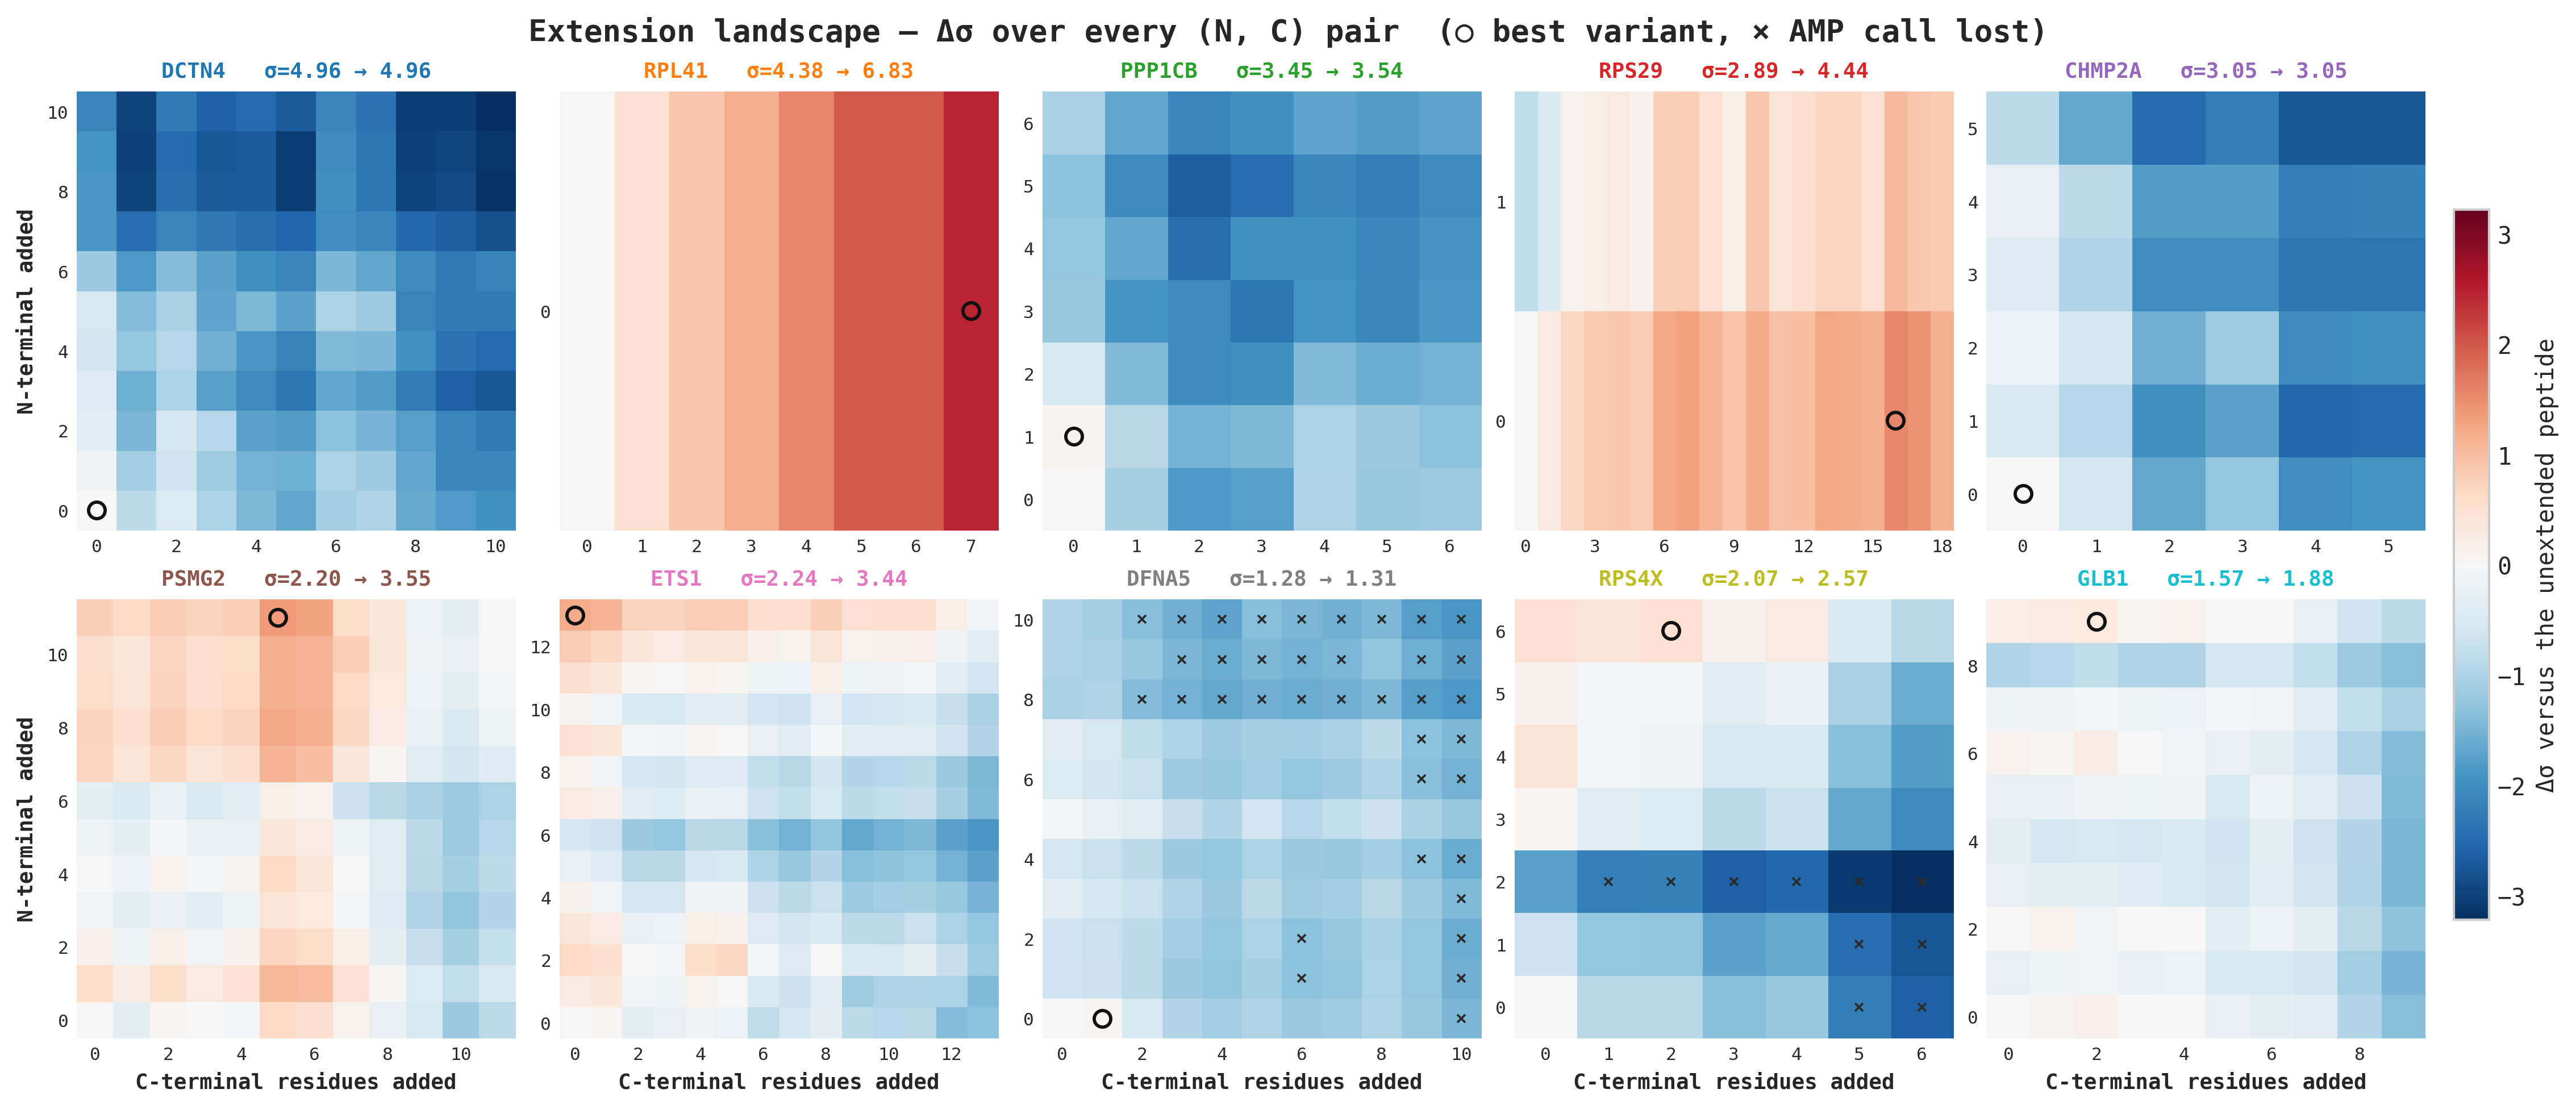

In [14]:
LIMIT = float(np.abs(insertion["delta_sigma"]).max())

figure, axes = plt.subplots(2, 5, figsize=(15.0, 6.4), dpi=300, layout="constrained")
for axis, peptide in zip(axes.flat, PEPTIDE_ORDER):
    subset = insertion[insertion["parent_id"] == peptide]
    grid = subset.pivot(index="left_added", columns="right_added", values="delta_sigma")
    image = axis.imshow(grid.to_numpy(), cmap="RdBu_r", vmin=-LIMIT, vmax=LIMIT,
                        origin="lower", aspect="auto")

    # An x marks a cell the model no longer calls AMP; the parent sits at (0, 0).
    dropped = subset[subset["pred"] == 0]
    if len(dropped):
        axis.plot(dropped["right_added"], dropped["left_added"], "x", color="#2b2b2b",
                  markersize=3.5, markeredgewidth=0.9, linestyle="none")
    peak = best.loc[peptide]
    axis.plot(peak["right_added"], peak["left_added"], "o", markersize=7,
              markerfacecolor="none", markeredgecolor="#111111", markeredgewidth=1.4)

    axis.set_title(f"{peptide}   σ={subset['parent_sigma'].iloc[0]:.2f} → {peak['sigma']:.2f}",
                   fontsize=9, fontweight="bold", pad=6, color=PEPTIDE_COLOR[peptide])
    axis.set_xticks(range(0, grid.shape[1], max(1, grid.shape[1] // 5)))
    axis.set_yticks(range(0, grid.shape[0], max(1, grid.shape[0] // 5)))
    axis.tick_params(labelsize=7.5, length=0, colors=SPINE_COLOR)
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)

for axis in axes[1]:
    axis.set_xlabel("C-terminal residues added", fontsize=9, fontweight="bold", labelpad=4)
for axis in axes[:, 0]:
    axis.set_ylabel("N-terminal added", fontsize=9, fontweight="bold", labelpad=4)

figure.colorbar(image, ax=axes, shrink=0.75, pad=0.012, label="Δσ versus the unextended peptide")
figure.suptitle("Extension landscape — Δσ over every (N, C) pair  "
                "(○ best variant, × AMP call lost)",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Single-terminus extension

The two edges of each landscape: the bottom row (C-terminal only) and the left column
(N-terminal only). The x axis is the **fraction of the peptide's own length added**, capped at
`max_flank_fraction = 0.5`, so an 11-mer growing by 5 and a 37-mer growing by 18 sit at the same
place. This is the comparable view to the deletion figure above, and the one to read if you want
to extend a candidate at one end only.

The **N panel's x axis runs right to left**, so the pair reads the way the peptide does — the N end on the left, the C end on the right, each one worked on from the outside in.

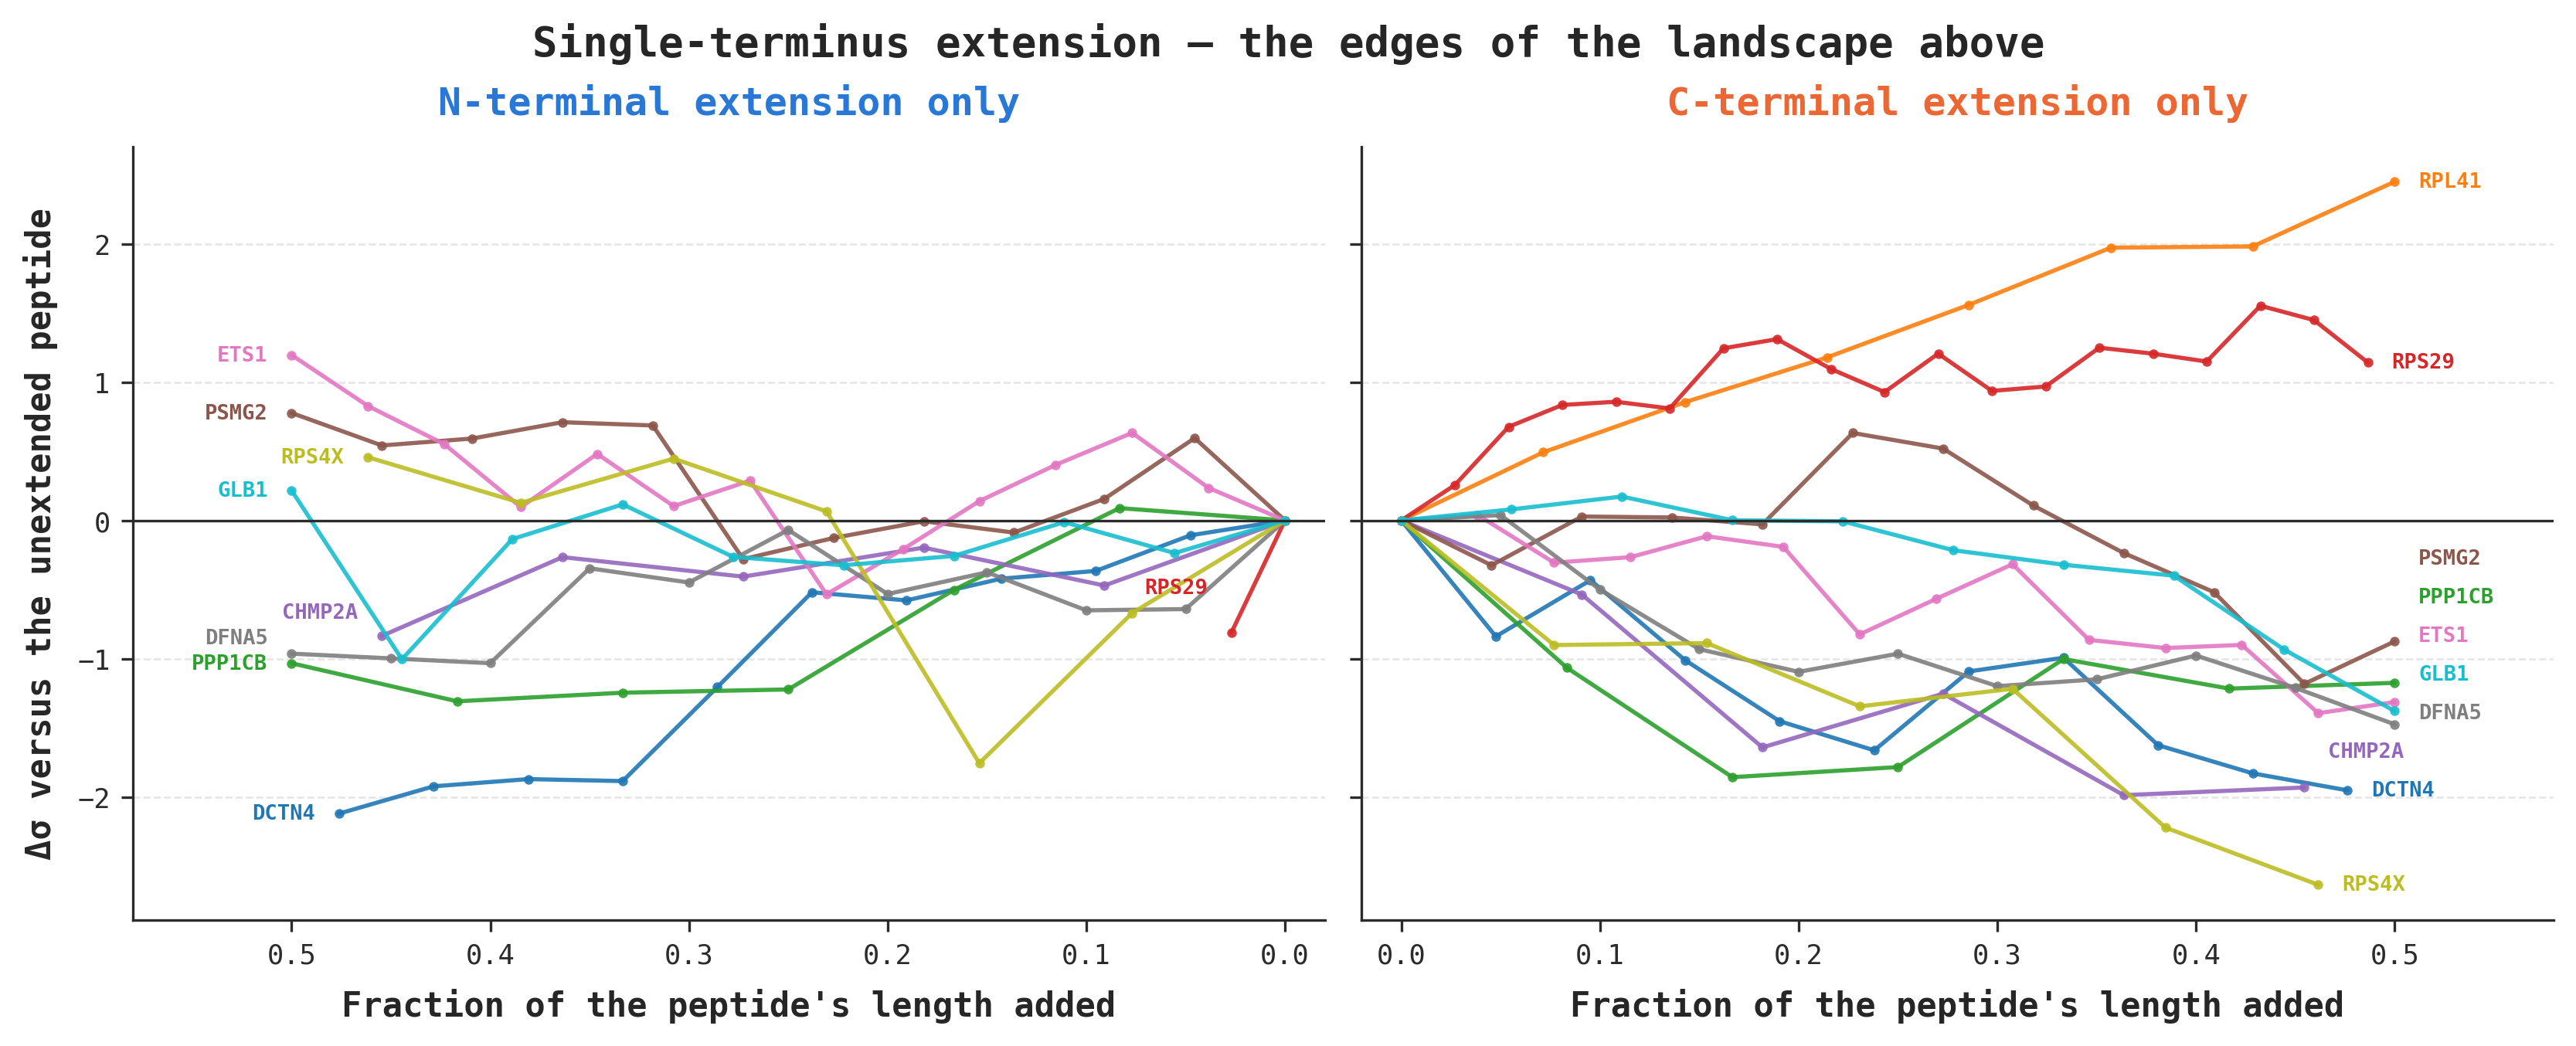

In [15]:
MARGINALS = [("N", insertion["right_added"] == 0, "left_added"),
             ("C", insertion["left_added"] == 0, "right_added")]

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.4), dpi=300, sharey=True, layout="constrained")
for axis, (terminus, mask, column) in zip(axes, MARGINALS):
    # Fraction of the peptide's own length, so a 37-mer growing by 18 and an 11-mer
    # growing by 5 sit on the same axis. max_flank_fraction caps it at 0.5.
    subset = insertion[mask].assign(fraction=lambda f: f[column] / f["core_length"])
    gap = (subset["delta_sigma"].max() - subset["delta_sigma"].min()) * 0.055
    ends = {}
    for peptide in PEPTIDE_ORDER:
        line = subset[subset["parent_id"] == peptide].sort_values("fraction")
        if len(line) < 2:
            continue
        axis.plot(line["fraction"], line["delta_sigma"], color=PEPTIDE_COLOR[peptide],
                  linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)
        ends[peptide] = (line["fraction"].iloc[-1], line["delta_sigma"].iloc[-1])

    # Lines end at different x, so the ladder runs over every label in the panel:
    # separating them vertically is what stops two labels landing on each other.
    ordered = sorted(ends, key=lambda peptide: ends[peptide][1])
    for peptide, height in zip(ordered, ladder_heights([ends[p][1] for p in ordered], gap)):
        position, value = ends[peptide]
        axis.annotate(peptide, xy=(position, value), xytext=(position + 0.012, height),
                      fontsize=6.5, fontweight="bold", color=PEPTIDE_COLOR[peptide],
                      va="center", ha="right" if terminus == "N" else "left",
                      annotation_clip=False)

    axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
    axis.set_title(f"{terminus}-terminal extension only", fontsize=TITLE_SIZE,
                   fontweight="bold", pad=10, color=TERMINUS_COLOR[terminus])
    axis.set_xlabel("Fraction of the peptide's length added", fontsize=LABEL_SIZE,
                    fontweight="bold", labelpad=6)
    # N grows leftwards out of the peptide, so its axis is mirrored.
    span = (-0.02, 0.58)
    axis.set_xlim(*(span[::-1] if terminus == "N" else span))
    axis.set_xticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    style_axes(axis)

axes[0].set_ylabel("Δσ versus the unextended peptide", fontsize=LABEL_SIZE,
                   fontweight="bold", labelpad=6)
figure.suptitle("Single-terminus extension — the edges of the landscape above",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Best variant reachable

The best σ found anywhere in each peptide's grid, against its unextended score. The annotation is
the extension that achieves it and the resulting length. RPL41 is the clearest case: seven
C-terminal residues take it from σ 4.38 to 6.83, the highest score anywhere in the set.

Note that this is the maximum over a sweep, not a held-out estimate — with 862 variants scored by
the same model that ranks them, some of the gain is the model's own noise. Treat the argmax as a
candidate to test, not as a measured improvement.

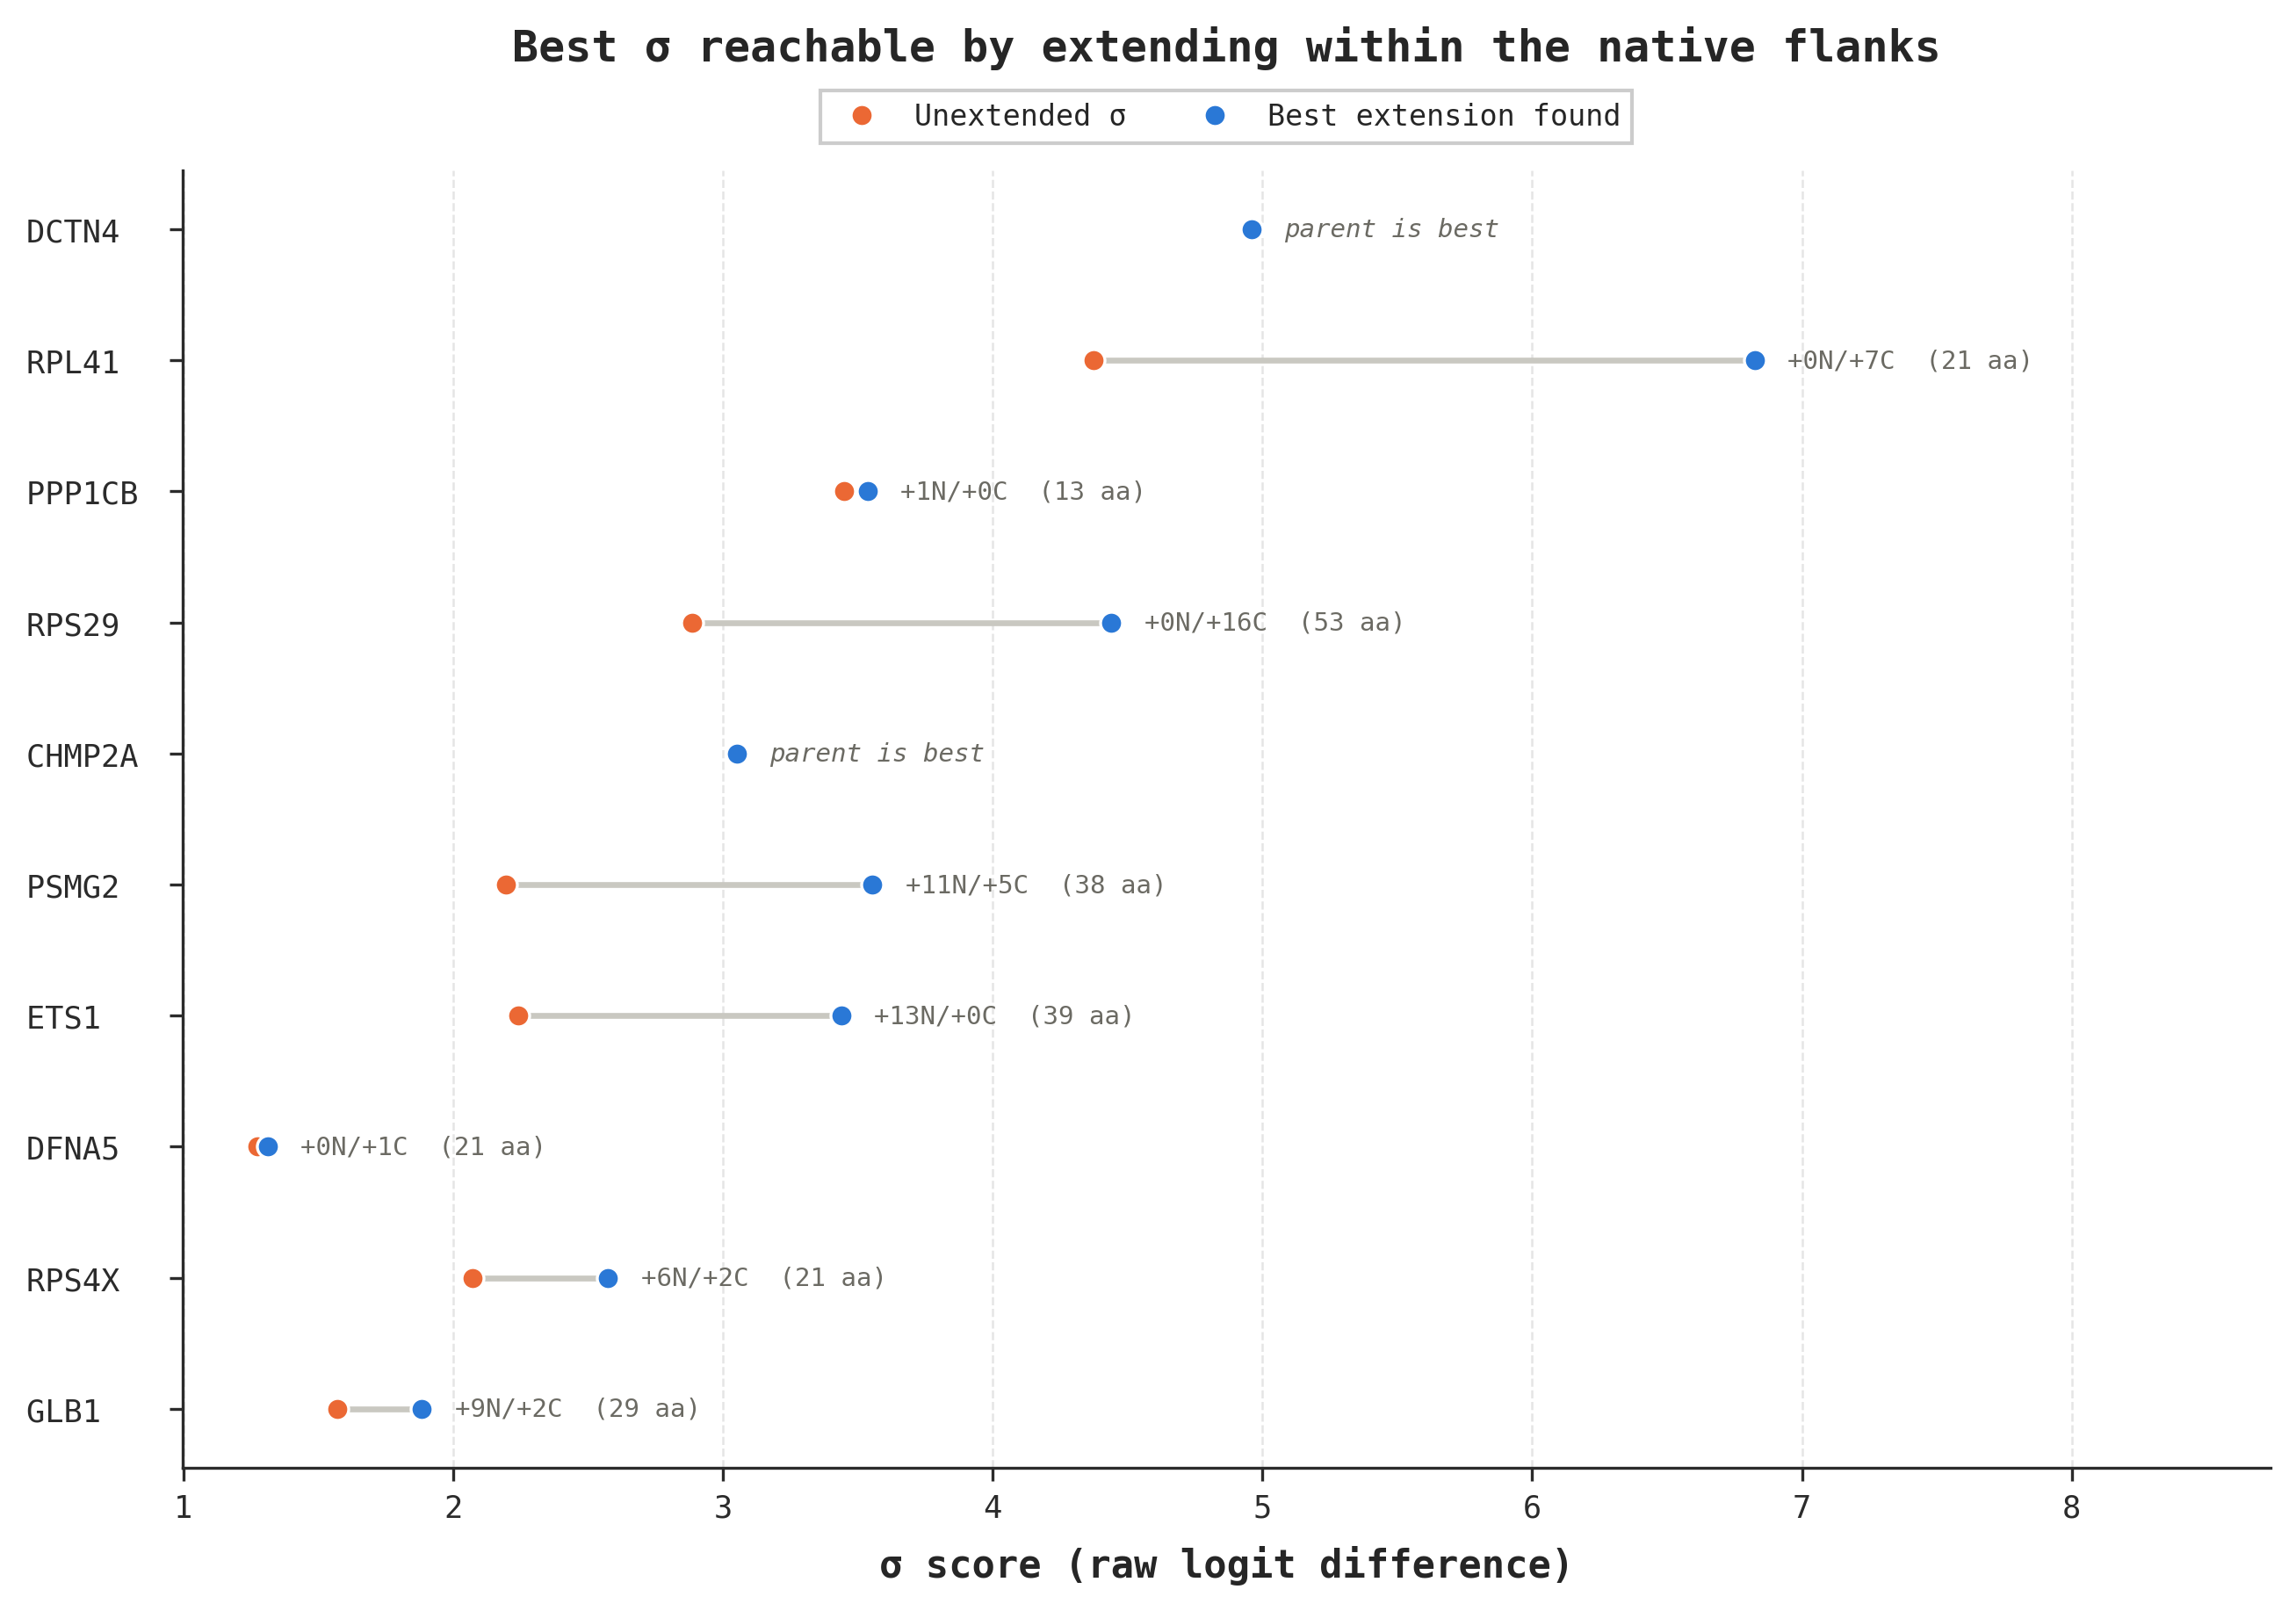

In [16]:
panel = best.loc[PEPTIDE_ORDER[::-1]]
positions = np.arange(len(panel))

figure, axis = plt.subplots(figsize=(8.6, 0.40 * len(panel) + 2.0), dpi=300, layout="constrained")
axis.hlines(positions, panel["parent_sigma"], panel["sigma"], color="#c9c8c1",
            linewidth=1.6, zorder=1)
axis.plot(panel["parent_sigma"], positions, "o", markersize=6, color="#eb6834",
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Unextended σ")
axis.plot(panel["sigma"], positions, "o", markersize=6, color="#2a78d6",
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Best extension found")

for position, row in zip(positions, panel.itertuples()):
    if row.delta_sigma > 1e-9:
        axis.annotate(f"+{row.left_added}N/+{row.right_added}C  ({row.variant_length} aa)",
                      xy=(row.sigma, position), textcoords="offset points", xytext=(9, 0),
                      fontsize=7, color="#6b6a63", va="center")
    else:
        axis.annotate("parent is best", xy=(row.sigma, position), textcoords="offset points",
                      xytext=(9, 0), fontsize=7, color="#6b6a63", va="center", style="italic")

axis.set_yticks(positions)
axis.set_yticklabels([f"{peptide:<7}" for peptide in panel.index])
axis.set_xlim(right=float(panel["sigma"].max()) * 1.28)
axis.set_xlabel("σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_title("Best σ reachable by extending within the native flanks",
               fontsize=TITLE_SIZE, fontweight="bold", pad=30)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, fontsize=8,
            frameon=True, fancybox=False, framealpha=1)
style_axes(axis, grid_axis="x")
plt.show()

## One length axis — both runs together

Truncation and single-terminus extension share a terminus and a baseline, so they share an axis:
negative is the fraction of the native length removed by the deletion run, positive is the
fraction added by the extension run, and zero is the native peptide. Working in fractions rather
than residues keeps the ten on one scale — the deletion run reaches −0.2 and the extension run
+0.5 for every one of them, whatever their length.

The **N panel is mirrored**: its extensions run out to the left and its truncations back to the right, so the two panels together show the peptide growing and shrinking from each of its own ends rather than both sharing one direction.

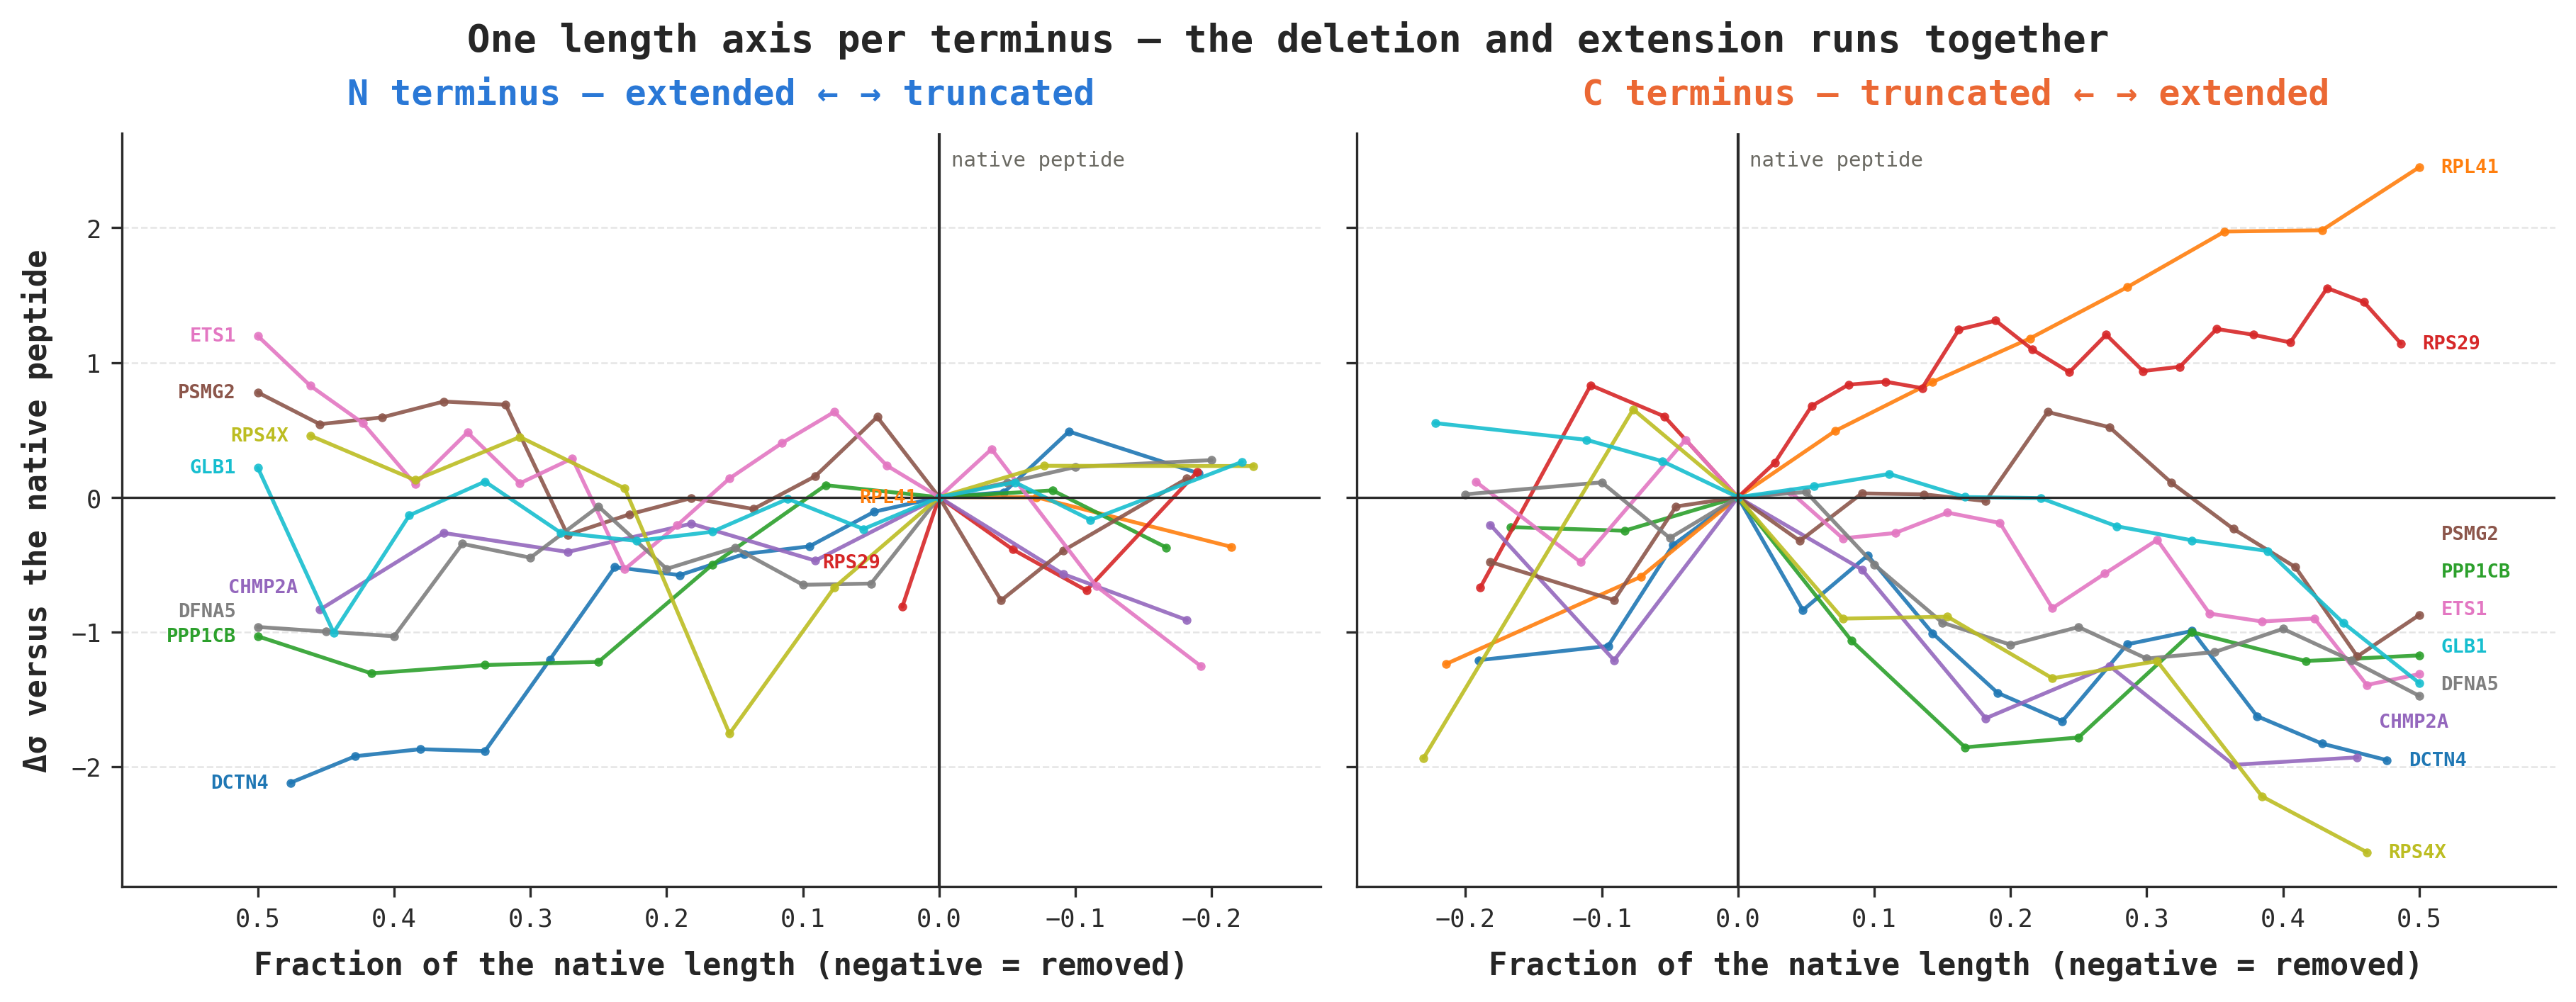

In [17]:
# Both runs fold into the same generated/length_cache, so their unextended parents
# agree and a deletion Δσ can share an axis with an extension Δσ. The axis is the
# fraction of the native length, negative for residues removed.
removed = deletion_curves.rename(columns={"terminus": "end"}).copy()
removed["fraction"] = -removed["k"] / removed["parent_length"]
added = pd.concat([
    insertion[insertion["right_added"] == 0].assign(end="N", change=lambda f: f["left_added"]),
    insertion[insertion["left_added"] == 0].assign(end="C", change=lambda f: f["right_added"]),
])
added["fraction"] = added["change"] / added["core_length"]
combined = pd.concat([removed[["parent_id", "end", "fraction", "delta_sigma"]],
                      added[["parent_id", "end", "fraction", "delta_sigma"]]])
combined = combined.drop_duplicates(["parent_id", "end", "fraction"])

figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.6), dpi=300, sharey=True, layout="constrained")
for axis, terminus in zip(axes, TERMINUS_ORDER):
    subset = combined[combined["end"] == terminus]
    gap = (subset["delta_sigma"].max() - subset["delta_sigma"].min()) * 0.055
    ends = {}
    for peptide in PEPTIDE_ORDER:
        line = subset[subset["parent_id"] == peptide].sort_values("fraction")
        axis.plot(line["fraction"], line["delta_sigma"], color=PEPTIDE_COLOR[peptide],
                  linewidth=1.3, marker="o", markersize=3, markeredgewidth=0, alpha=0.9)
        ends[peptide] = (line["fraction"].iloc[-1], line["delta_sigma"].iloc[-1])

    # Lines end at different x, so the ladder runs over every label in the panel:
    # separating them vertically is what stops two labels landing on each other.
    ordered = sorted(ends, key=lambda peptide: ends[peptide][1])
    for peptide, height in zip(ordered, ladder_heights([ends[p][1] for p in ordered], gap)):
        position, value = ends[peptide]
        axis.annotate(peptide, xy=(position, value), xytext=(position + 0.016, height),
                      fontsize=6.5, fontweight="bold", color=PEPTIDE_COLOR[peptide],
                      va="center", ha="right" if terminus == "N" else "left",
                      annotation_clip=False)

    axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
    axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
    axis.annotate("native peptide", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
                  textcoords="offset points", xytext=(4, -11), fontsize=7, color="#6b6a63")
    # Mirrored for N, so the pair reads outwards from the peptide: the N end grows
    # to the left and is cut back to the right, the C end the other way about.
    direction = "extended ← → truncated" if terminus == "N" else "truncated ← → extended"
    axis.set_title(f"{terminus} terminus — {direction}", fontsize=TITLE_SIZE,
                   fontweight="bold", pad=10, color=TERMINUS_COLOR[terminus])
    axis.set_xlabel("Fraction of the native length (negative = removed)", fontsize=LABEL_SIZE,
                    fontweight="bold", labelpad=6)
    axis.set_xticks([-0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    span = (-0.28, 0.60)
    axis.set_xlim(*(span[::-1] if terminus == "N" else span))
    style_axes(axis)

axes[0].set_ylabel("Δσ versus the native peptide", fontsize=LABEL_SIZE,
                   fontweight="bold", labelpad=6)
figure.suptitle("One length axis per terminus — the deletion and extension runs together",
                fontsize=TITLE_SIZE + 1, fontweight="bold")
plt.show()

### Caveat — the mutation section's baseline is not byte-identical

The three runs do not all fold from the same place. The mutation run reuses
`generated/structures/<gene>.pdb`, folded one peptide at a time; the two length runs fold into
`generated/length_cache` with `fold_batch_size = 16`. ESMFold in fp16 reduces in an order that
depends on the batch dimension, so a batch-folded structure is not bitwise equal to a
single-folded one.

For eight of the ten that makes no difference at all — the parent σ matches to within 1e-6. Two
differ: **DFNA5** by 0.319 σ (1.594 → 1.276) and **RPL41** by 0.099. Both are low-confidence folds
where small coordinate differences move the contact graph. So compare Δ values across sections
freely, but do not read a peptide's absolute σ in the mutation section against its σ here.

The deletion and extension runs share the one cache and agree on every parent to 5e-7, which is
CSV float rounding, so the combined axis above is sound.

The figures quoted here describe the runs named at the top of the notebook. Both loader cells reprint the gaps live, so a later run — a refold at a different precision, say — shows its own numbers there even while this text stays as written.

## Overall ranking — σ held and calls kept across all three perturbations

One row per candidate, **ranked by `σ mean after change`**: the score it holds up on average once
mutation, truncation and extension have been applied to it.

| Column | What it is |
|---|---|
| `σ unperturbed` | The native peptide's own σ, nothing done to it. The AMP threshold is 0. |
| `P(AMP) unperturbed` | The same score as a probability, `sigmoid(σ / T)`. The threshold is 0.5. |
| `σ mean after change` | Where it sits on average after perturbation — `σ unperturbed + Δσ mean change`. This is the ranking column. |
| `P(AMP) after change` | That mean σ as a probability. |
| `Δσ mean change` | Mean shift in σ caused by perturbation. Negative is a loss; the three perturbations carry equal weight. |
| `ΔP(AMP) change` | The same loss in probability units. |
| `retention: mutation` | Share of its 4,500 mutants still called AMP, under its **weakest** scheme. |
| `retention: deletion` | Share of its truncations still called AMP, both termini pooled. |
| `retention: insertion` | Share of its whole left × right extension grid still called AMP. |
| `retention: overall` | Mean of the three retentions. |

The two halves of the table answer different questions. **Retention** asks how often a candidate
stays on the AMP side of the line; **σ after change** asks how much margin it keeps. They do not
agree: DCTN4 has the best retention of the ten but loses the most σ (−1.42), while RPL41 gives up
almost nothing (−0.36) and ends up highest.

Each perturbation is averaged on its own before the three are combined, because pooling raw
variants would let the 4,500 mutants drown out the 6 truncations.

Each `P(AMP)` column is `sigmoid(σ / T)` of the σ column beside it, with `T = 0.82068` read from
the checkpoint — the transform **of that mean**, not the mean of the per-variant probabilities.
The two differ because the sigmoid is not linear, and the probability scale compresses hard at the
top: DCTN4 gives up 1.42 σ and only 0.011 of P(AMP), because it starts at 0.998 where there is
almost nothing left to lose. σ is the honest axis for comparing losses; P(AMP) is the readable one
for judging whether a call is safe.

Two limits worth holding in mind:

- **The three probes are not equally severe.** Mutation reaches `p = 0.5` and extension adds up to
  50% per side, but this deletion run stops at `p = 0.2` — at most 7 residues, and only 2 for the
  shortest peptides. Deletion separates nobody here: every truncation keeps the call, so that
  retention column is 1.000 for all ten. A deeper deletion run would change this ranking.
- **σ here is the length runs' baseline.** For DFNA5 and RPL41 the mutation run folded its own copy
  and started from a slightly different σ (see the caveat above), so their mutation contribution is
  carried over as a Δ rather than as an absolute score.

In [18]:
# Retention = the share of a peptide's variants still called AMP (sigma > 0).
# Mutation is read on its weakest scheme, deletion pools both termini, extension
# uses its whole left x right grid.
worst_scheme = robustness.loc[robustness.groupby("parent_id")["retention_auc"].idxmin()] \
    .set_index("parent_id")["scheme"]
worst_curves = curves[[scheme == worst_scheme[peptide] for peptide, scheme
                       in zip(curves["parent_id"], curves["scheme"])]]

retention = pd.DataFrame({
    "mutation": robustness.groupby("parent_id")["retention_auc"].min(),
    "deletion": deletion_curves.groupby("parent_id")["pred"].mean(),
    "insertion": insertion.groupby("parent_id")["pred"].mean(),
})
# Each perturbation is averaged on its own first, then the three are weighted equally -
# pooling raw variants would make the 4,500 mutants drown the 6 truncations.
delta = pd.DataFrame({
    "mutation": worst_curves.groupby("parent_id")["delta_sigma"].mean(),
    "deletion": deletion_curves.groupby("parent_id")["delta_sigma"].mean(),
    "insertion": insertion.groupby("parent_id")["delta_sigma"].mean(),
})


def prob_amp(sigma):
    """The run's own calibration: P(AMP) = sigmoid(sigma / T), T from the checkpoint."""
    return 1.0 / (1.0 + np.exp(-sigma / TEMPERATURE))


summary = pd.DataFrame({"σ unperturbed": deletion_parents})
summary["σ mean after change"] = summary["σ unperturbed"] + delta.mean(axis=1)
summary["Δσ mean change"] = delta.mean(axis=1)
summary.insert(1, "P(AMP) unperturbed", prob_amp(summary["σ unperturbed"]))
summary.insert(3, "P(AMP) after change", prob_amp(summary["σ mean after change"]))
summary["ΔP(AMP) change"] = summary["P(AMP) after change"] - summary["P(AMP) unperturbed"]
for name in ("mutation", "deletion", "insertion"):
    summary[f"retention: {name}"] = retention[name]
summary["retention: overall"] = retention.mean(axis=1)
summary = summary.sort_values("σ mean after change", ascending=False)
summary.index.name = "candidate"

print("σ columns are the raw logit difference; each P(AMP) column is sigmoid(σ / T) of the σ "
      f"beside it,\nwith T = {TEMPERATURE:.5f} from the checkpoint — the transform of that mean, "
      "not the mean of the\nper-variant probabilities, which differ because the sigmoid is not "
      "linear.")
display(summary.style
        .format({"σ unperturbed": "{:.3f}", "σ mean after change": "{:.3f}",
                 "Δσ mean change": "{:+.3f}", "P(AMP) unperturbed": "{:.3f}",
                 "P(AMP) after change": "{:.3f}", "ΔP(AMP) change": "{:+.3f}",
                 "retention: mutation": "{:.3f}", "retention: deletion": "{:.3f}",
                 "retention: insertion": "{:.3f}", "retention: overall": "{:.3f}"})
        .background_gradient(cmap="YlGnBu", subset=["σ mean after change"])
        .background_gradient(cmap="YlGnBu", subset=["retention: overall"], vmin=0.5, vmax=1.0))

σ columns are the raw logit difference; each P(AMP) column is sigmoid(σ / T) of the σ beside it,
with T = 0.82068 from the checkpoint — the transform of that mean, not the mean of the
per-variant probabilities, which differ because the sigmoid is not linear.


,σ unperturbed,P(AMP) unperturbed,σ mean after change,P(AMP) after change,Δσ mean change,ΔP(AMP) change,retention: mutation,retention: deletion,retention: insertion,retention: overall
candidate,,,,,,,,,,
RPL41,4.376,0.995,4.017,0.993,-0.358,-0.003,0.890,1.000,1.000,0.963
DCTN4,4.960,0.998,3.541,0.987,-1.419,-0.011,0.965,1.000,1.000,0.988
RPS29,2.887,0.971,2.653,0.962,-0.234,-0.009,0.857,1.000,1.000,0.952
PPP1CB,3.448,0.985,2.224,0.938,-1.224,-0.048,0.829,1.000,1.000,0.943
PSMG2,2.196,0.936,1.702,0.888,-0.494,-0.047,0.733,1.000,1.000,0.911
CHMP2A,3.052,0.976,1.602,0.876,-1.450,-0.101,0.757,1.000,1.000,0.919
ETS1,2.243,0.939,1.551,0.869,-0.691,-0.070,0.677,1.000,1.000,0.892
RPS4X,2.074,0.926,1.275,0.825,-0.799,-0.101,0.646,1.000,0.796,0.814
GLB1,1.572,0.872,1.157,0.804,-0.416,-0.068,0.631,1.000,1.000,0.877


## Top ten variants found

Every variant from the two length runs in one pool — 852 extensions and 60 truncations over the
ten candidates — ranked by σ. The mutation run is **not** in this pool: it writes per-cell means
over 500 replicates rather than the individual mutants, so its rows are not the same kind of
object as these.

| Column | What it is |
|---|---|
| `candidate` | The native peptide this variant came from. |
| `run` | Which sweep produced it, extension or deletion. |
| `what changed` | `+nN/+nC` residues added at each end, or `-kN` / `-kC` residues cut from one end. |
| `length` | The variant's own length in residues. |
| `σ`, `P(AMP)` | Its score, raw and as a probability. |
| `Δσ vs native` | How much better or worse than the peptide it came from. |

The ten are concentrated in two candidates, which is itself the finding: **RPL41** grows into a
C-terminal flank that is almost pure lysine and arginine (`…KRKRRKMR`), and the model rewards every
residue of it, while **DCTN4** gains by having its first one to four residues cut away rather than
by growing. The best variant of each of the ten is in the dumbbell figure above.

As with that figure, this is the maximum over a sweep scored by the model doing the ranking, so
some of the margin at the top is the model's own noise. These are candidates to test, not measured
improvements.

In [19]:
# One row per variant, pooled over the two length runs. Mutation is left out: that run
# writes per-cell means over 500 replicates, not the individual mutants, so its rows
# are not the same kind of object as these.
extensions = insertion[(insertion["left_added"] > 0) | (insertion["right_added"] > 0)].assign(
    change=lambda frame: ["+%dN/+%dC" % pair
                          for pair in zip(frame["left_added"], frame["right_added"])],
    run="extension",
)
truncations = deletion_curves.assign(
    change=lambda frame: ["-%d%s" % pair for pair in zip(frame["k"], frame["terminus"])],
    run="deletion",
)
COLUMNS = ["parent_id", "run", "change", "variant_length", "sequence",
           "sigma", "prob_AMP", "delta_sigma"]
pool = (pd.concat([extensions[COLUMNS], truncations[COLUMNS]])
        .drop_duplicates(["parent_id", "sequence"]))

top_variants = pool.nlargest(10, "sigma").reset_index(drop=True)
top_variants.insert(0, "rank", np.arange(1, len(top_variants) + 1))
top_variants = top_variants.rename(columns={
    "parent_id": "candidate", "change": "what changed", "variant_length": "length",
    "sigma": "σ", "prob_AMP": "P(AMP)", "delta_sigma": "Δσ vs native",
})

leaders = top_variants["candidate"].value_counts()
print(f"Pool: {len(pool)} distinct variants "
      f"({len(extensions)} extensions, {len(truncations)} truncations) over "
      f"{pool['parent_id'].nunique()} candidates.")
print("Top ten are concentrated: " + ", ".join(f"{name} x{count}" for name, count in leaders.items())
      + ". The best variant of each candidate is in the dumbbell above.")
display(top_variants.style.format({"σ": "{:.3f}", "P(AMP)": "{:.4f}", "Δσ vs native": "{:+.3f}"})
        .background_gradient(cmap="YlGnBu", subset=["σ"]).hide(axis="index"))

Pool: 904 distinct variants (852 extensions, 60 truncations) over 10 candidates.
Top ten are concentrated: RPL41 x7, DCTN4 x3. The best variant of each candidate is in the dumbbell above.


rank,candidate,run,what changed,length,sequence,σ,P(AMP),Δσ vs native
1,RPL41,extension,+0N/+7C,21,MRAKWRKKRMRRLKRKRRKMR,6.825,0.9998,+2.450
2,RPL41,extension,+0N/+6C,20,MRAKWRKKRMRRLKRKRRKM,6.357,0.9996,+1.982
3,RPL41,extension,+0N/+5C,19,MRAKWRKKRMRRLKRKRRK,6.348,0.9996,+1.972
4,RPL41,extension,+0N/+4C,18,MRAKWRKKRMRRLKRKRR,5.935,0.9993,+1.559
5,RPL41,extension,+0N/+3C,17,MRAKWRKKRMRRLKRKR,5.554,0.9989,+1.179
6,DCTN4,deletion,-2N,19,LYPRHKHLLIKRSLRCRKC,5.447,0.9987,+0.488
7,RPL41,extension,+0N/+2C,16,MRAKWRKKRMRRLKRK,5.231,0.9983,+0.855
8,DCTN4,deletion,-4N,17,PRHKHLLIKRSLRCRKC,5.137,0.9981,+0.177
9,DCTN4,deletion,-1N,20,QLYPRHKHLLIKRSLRCRKC,4.996,0.9977,+0.036
10,RPL41,extension,+0N/+1C,15,MRAKWRKKRMRRLKR,4.868,0.9974,+0.493
